# Facial Emotion Recognition — VGG-16 + Attention (FER2013 + CK+)
## Modalitas 1: Ekspresi Wajah
### Made Pranajaya Dibyacita | NIM 2208561122 | Universitas Udayana
---
Notebook ini mengimplementasikan Facial Emotion Recognition (FER) menggunakan arsitektur VGG-16 dengan transfer learning, dilengkapi Squeeze-and-Excitation attention block dan Spatial Attention (CBAM-inspired), dilatih pada gabungan dataset FER2013 dan CK+ Extended.

**Target akurasi** mengacu pada state-of-the-art terkini yang melampaui human-level baseline (~65%) pada FER2013.

**Referensi Arsitektur & Teknik:**
- Khaireddin & Chen (2021) — VGG-13 Fine-Tuned, *arXiv:2105.03588* — 73.28% FER2013
- Li et al. (2021) — DDAMFN, *IEEE TAFF* — 76.7% FER2013
- Wang et al. (2020) — SCN Self-Cure Network, *CVPR* — 74.42% FER2013
- Hu et al. (2018) — Squeeze-and-Excitation Networks, *CVPR Best Paper*
- Woo et al. (2018) — CBAM, *ECCV*
- Zhang et al. (2022) — APViT, *IEEE TIP* — 76.36% FER2013

**Strategi utama:**
- **tf.data pipeline** — preprocessing on-the-fly, tidak muat seluruh float32 dataset ke RAM
- Transfer learning VGG-16 (ImageNet) + progressive fine-tuning 4 fase
- SE Block + Spatial Attention (CBAM-inspired)
- CLAHE pada preprocessing CK+, augmentasi agresif via tf.image
- Class-weight balancing untuk distribusi imbalanced
- Bayesian hyperparameter tuning (20 trial)
- Test-Time Augmentation (TTA) untuk inference


In [1]:
#!pip install keras-tuner opencv-python-headless psutil -q
#print('Dependencies ready.')

In [2]:
import os, json, warnings, gc, time
import numpy as np
import pandas as pd
import psutil
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from tqdm import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, classification_report,
                             f1_score, precision_score, recall_score,
                             roc_curve, auc)
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, regularizers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.callbacks import (ModelCheckpoint, EarlyStopping,
                                        ReduceLROnPlateau, CSVLogger)
from tensorflow.keras.utils import to_categorical
import keras_tuner as kt

warnings.filterwarnings('ignore')
np.random.seed(42)
tf.random.set_seed(42)

def ram_gb():
    return psutil.virtual_memory().used / 1e9

print(f'TensorFlow  : {tf.__version__}')
print(f'Keras-Tuner : {kt.__version__}')
print(f'GPU         : {tf.config.list_physical_devices("GPU")}')
print(f'RAM used    : {ram_gb():.2f} GB / {psutil.virtual_memory().total/1e9:.1f} GB')

I0000 00:00:1776514172.686741   27879 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1776514172.724447   27879 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1776514173.509582   27879 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow  : 2.21.0
Keras-Tuner : 1.4.8
GPU         : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
RAM used    : 6.58 GB / 16.6 GB


In [3]:
# Path lokal proyek — untuk Kaggle ganti ke /kaggle/input/<slug>/ dan /kaggle/working/
BASE_DIR      = '/media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5'
FER_TRAIN     = os.path.join(BASE_DIR, 'dataset/fer2013/train')
FER_TEST      = os.path.join(BASE_DIR, 'dataset/fer2013/test')
CKPLUS_CSV    = os.path.join(BASE_DIR, 'dataset/ck+/ckextended.csv')

OUTPUT_DIR    = os.path.join(BASE_DIR, 'output')
PLOT_DIR      = os.path.join(OUTPUT_DIR, 'plots')
MODEL_DIR     = os.path.join(OUTPUT_DIR, 'models')
HP_DIR        = os.path.join(OUTPUT_DIR, 'hp_tuning')
LOG_DIR       = os.path.join(OUTPUT_DIR, 'logs')
CK_IMG_DIR    = os.path.join(OUTPUT_DIR, 'ck_temp')  # CK+ pixel CSV -> PNG files

for d in [OUTPUT_DIR, PLOT_DIR, MODEL_DIR, HP_DIR, LOG_DIR, CK_IMG_DIR]:
    os.makedirs(d, exist_ok=True)

IMG_SIZE      = 224
BATCH_SIZE    = 32
LABEL_SMOOTH  = 0.1
TTA_STEPS     = 10

# Fase training
EPOCHS_FROZEN = 10
EPOCHS_FT1    = 15
EPOCHS_FT2    = 15
EPOCHS_FT3    = 20
LR_FROZEN     = 1e-3
LR_FT1        = 5e-5
LR_FT2        = 2e-5
LR_FT3        = 1e-5

EMOTIONS      = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
NUM_CLASSES   = len(EMOTIONS)
EMOTION_IDX   = {e: i for i, e in enumerate(EMOTIONS)}
CK_MAP        = {0:'angry', 1:'disgust', 2:'fear', 3:'happy', 4:'sad', 5:'surprise', 6:'neutral'}

print('Config ready.')
print(f'RAM used: {ram_gb():.2f} GB')

Config ready.
RAM used: 6.58 GB


## 1. Load & Combine Dataset

Saya simpan CK+ pixel values sebagai file PNG ke disk (dengan CLAHE), lalu kumpulkan semua path file untuk FER2013 dan CK+. Strategi ini memastikan hanya path yang ada di RAM — gambar dimuat on-the-fly saat training.

In [4]:
# CK+ Extended: parse pixel values dari CSV, apply CLAHE, simpan sebagai PNG
# Ini hanya perlu dijalankan sekali — cek apakah sudah ada
existing_ck = [f for f in os.listdir(CK_IMG_DIR) if f.endswith('.png')]

if len(existing_ck) > 0:
    print(f'CK+ PNG sudah ada: {len(existing_ck)} files. Skip re-processing.')
else:
    ck_df = pd.read_csv(CKPLUS_CSV)
    print(f'CK+ rows: {len(ck_df)} | columns: {ck_df.columns.tolist()}')
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4))
    saved = 0
    for idx, row in tqdm(ck_df.iterrows(), total=len(ck_df), desc='Saving CK+ PNGs'):
        emotion_id = int(row['emotion'])
        if emotion_id not in CK_MAP:
            continue
        emotion_name = CK_MAP[emotion_id]
        pixels = np.array(row['pixels'].split(), dtype=np.uint8).reshape(48, 48)
        pixels = clahe.apply(pixels)
        img_rgb = cv2.cvtColor(pixels, cv2.COLOR_GRAY2RGB)
        fname   = f'ck_{idx:05d}_{emotion_name}.png'
        cv2.imwrite(os.path.join(CK_IMG_DIR, fname), img_rgb)
        saved += 1
    print(f'Saved {saved} CK+ PNG files -> {CK_IMG_DIR}')

# Pastikan ck_df ada untuk EDA downstream
ck_df = pd.read_csv(CKPLUS_CSV)
print(f'RAM used: {ram_gb():.2f} GB')

CK+ PNG sudah ada: 902 files. Skip re-processing.
RAM used: 6.59 GB


In [5]:
# Kumpulkan path file dan label — tidak ada gambar yang dimuat ke RAM di sini
all_paths, all_labels = [], []

# FER2013 train
for emotion in EMOTIONS:
    edir = os.path.join(FER_TRAIN, emotion)
    if not os.path.isdir(edir):
        continue
    for fname in os.listdir(edir):
        if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
            all_paths.append(os.path.join(edir, fname))
            all_labels.append(EMOTION_IDX[emotion])

print(f'FER2013 train paths: {len(all_paths)}')

# CK+ (dari folder PNG yang sudah dibuat)
ck_count = 0
for fname in os.listdir(CK_IMG_DIR):
    if not fname.endswith('.png'):
        continue
    parts = fname.replace('.png', '').split('_')
    emotion_name = parts[-1]
    if emotion_name in EMOTION_IDX:
        all_paths.append(os.path.join(CK_IMG_DIR, fname))
        all_labels.append(EMOTION_IDX[emotion_name])
        ck_count += 1

print(f'CK+ paths added   : {ck_count}')
print(f'Total train paths : {len(all_paths)}')

# FER2013 test — terpisah, untuk evaluasi murni
test_paths, test_labels = [], []
for emotion in EMOTIONS:
    edir = os.path.join(FER_TEST, emotion)
    if not os.path.isdir(edir):
        continue
    for fname in os.listdir(edir):
        if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
            test_paths.append(os.path.join(edir, fname))
            test_labels.append(EMOTION_IDX[emotion])

print(f'FER2013 test paths : {len(test_paths)}')
print(f'RAM used           : {ram_gb():.2f} GB')

FER2013 train paths: 28709
CK+ paths added   : 902
Total train paths : 29611
FER2013 test paths : 7178
RAM used           : 6.59 GB


In [6]:
# Split train/val dari path list (stratified, 10% val)
all_paths  = np.array(all_paths)
all_labels = np.array(all_labels, dtype=np.int32)
test_paths  = np.array(test_paths)
test_labels = np.array(test_labels, dtype=np.int32)

train_paths, val_paths, train_labels, val_labels = train_test_split(
    all_paths, all_labels, test_size=0.10, random_state=42, stratify=all_labels
)

print(f'Train : {len(train_paths)} paths')
print(f'Val   : {len(val_paths)} paths')
print(f'Test  : {len(test_paths)} paths')
print(f'Total : {len(train_paths)+len(val_paths)+len(test_paths)} samples')
print(f'RAM used: {ram_gb():.2f} GB  <- jauh lebih rendah dari sebelumnya')

# Distribusi per split
for split_name, lbls in [('Train', train_labels), ('Val', val_labels), ('Test', test_labels)]:
    dist = {EMOTIONS[i]: int(np.sum(lbls==i)) for i in range(NUM_CLASSES)}
    print(f'  {split_name}: {dist}')

Train : 26649 paths
Val   : 2962 paths
Test  : 7178 paths
Total : 36789 samples
RAM used: 6.62 GB  <- jauh lebih rendah dari sebelumnya
  Train: {'angry': 3636, 'disgust': 445, 'fear': 3710, 'happy': 6555, 'neutral': 5002, 'sad': 4372, 'surprise': 2929}
  Val: {'angry': 404, 'disgust': 50, 'fear': 412, 'happy': 729, 'neutral': 556, 'sad': 486, 'surprise': 325}
  Test: {'angry': 958, 'disgust': 111, 'fear': 1024, 'happy': 1774, 'neutral': 1233, 'sad': 1247, 'surprise': 831}


## 2. Exploratory Data Analysis

Saya muat subset kecil gambar (100 per kelas) khusus untuk visualisasi EDA — setelah selesai langsung dihapus dari memory. Gambar tidak pernah dimuat sekaligus ke RAM.

In [7]:
# Muat 80 sample per kelas untuk EDA — hanya ~560 gambar × 224×224×3 uint8 ≈ ~85 MB
N_EDA = 80
eda_images, eda_labels = [], []

# Kelompokkan path per kelas
paths_by_class = {i: [] for i in range(NUM_CLASSES)}
for p, l in zip(all_paths, all_labels):
    paths_by_class[l].append(p)

for emo_idx in range(NUM_CLASSES):
    pool = paths_by_class[emo_idx]
    selected = np.random.choice(pool, size=min(N_EDA, len(pool)), replace=False)
    for fpath in selected:
        img = cv2.imread(fpath)
        if img is None:
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_CUBIC)
        eda_images.append(img)
        eda_labels.append(emo_idx)

eda_images = np.array(eda_images, dtype=np.uint8)
eda_labels = np.array(eda_labels, dtype=np.int32)

print(f'EDA images loaded: {eda_images.shape}  ({eda_images.nbytes/1e6:.1f} MB)')
print(f'RAM used: {ram_gb():.2f} GB')

EDA images loaded: (560, 224, 224, 3)  (84.3 MB)
RAM used: 6.78 GB


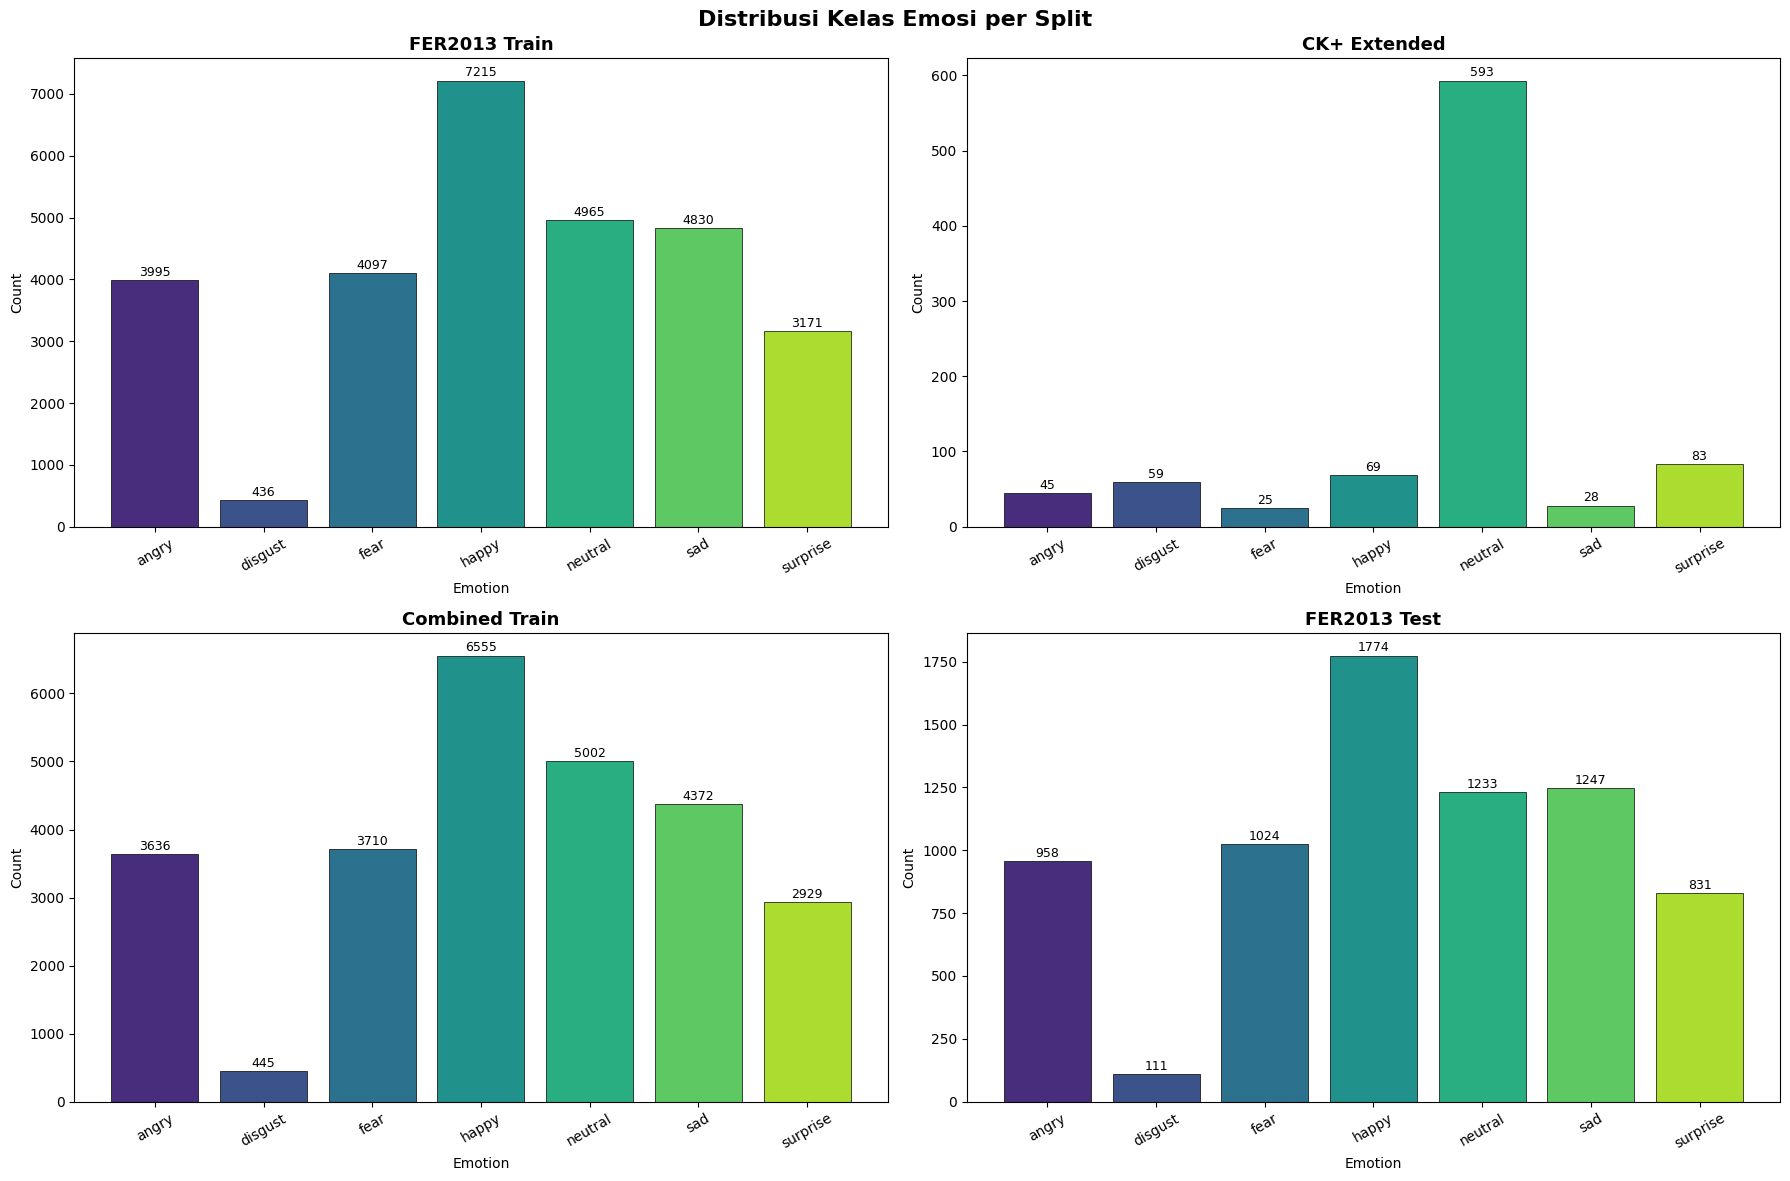

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/plots/01_class_distribution.png


In [8]:
# Distribusi kelas per split — dari label arrays (tidak perlu load gambar)
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('Distribusi Kelas Emosi per Split', fontsize=16, fontweight='bold')

fer_train_labels = all_labels[all_labels < 7]  # semua memang <7
ck_label_counts  = [ck_count_per_class for ck_count_per_class in
                    [sum(1 for f in os.listdir(CK_IMG_DIR)
                         if f.endswith('.png') and f.split('_')[-1].replace('.png','') == e)
                     for e in EMOTIONS]]

datasets_info = [
    ([int(np.sum(all_labels==i)) - ck_label_counts[i] for i in range(NUM_CLASSES)],
     'FER2013 Train', axes[0,0]),
    (ck_label_counts,                                   'CK+ Extended',  axes[0,1]),
    ([int(np.sum(train_labels==i)) for i in range(NUM_CLASSES)],
     'Combined Train', axes[1,0]),
    ([int(np.sum(test_labels==i)) for i in range(NUM_CLASSES)],
     'FER2013 Test',   axes[1,1]),
]

palette = sns.color_palette('viridis', NUM_CLASSES)

for counts, title, ax in datasets_info:
    bars = ax.bar(EMOTIONS, counts, color=palette, edgecolor='black', linewidth=0.5)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('Emotion'); ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=30)
    for bar, cnt in zip(bars, counts):
        ax.annotate(str(cnt), xy=(bar.get_x()+bar.get_width()/2, bar.get_height()),
                    xytext=(0,3), textcoords='offset points', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/01_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {PLOT_DIR}/01_class_distribution.png')

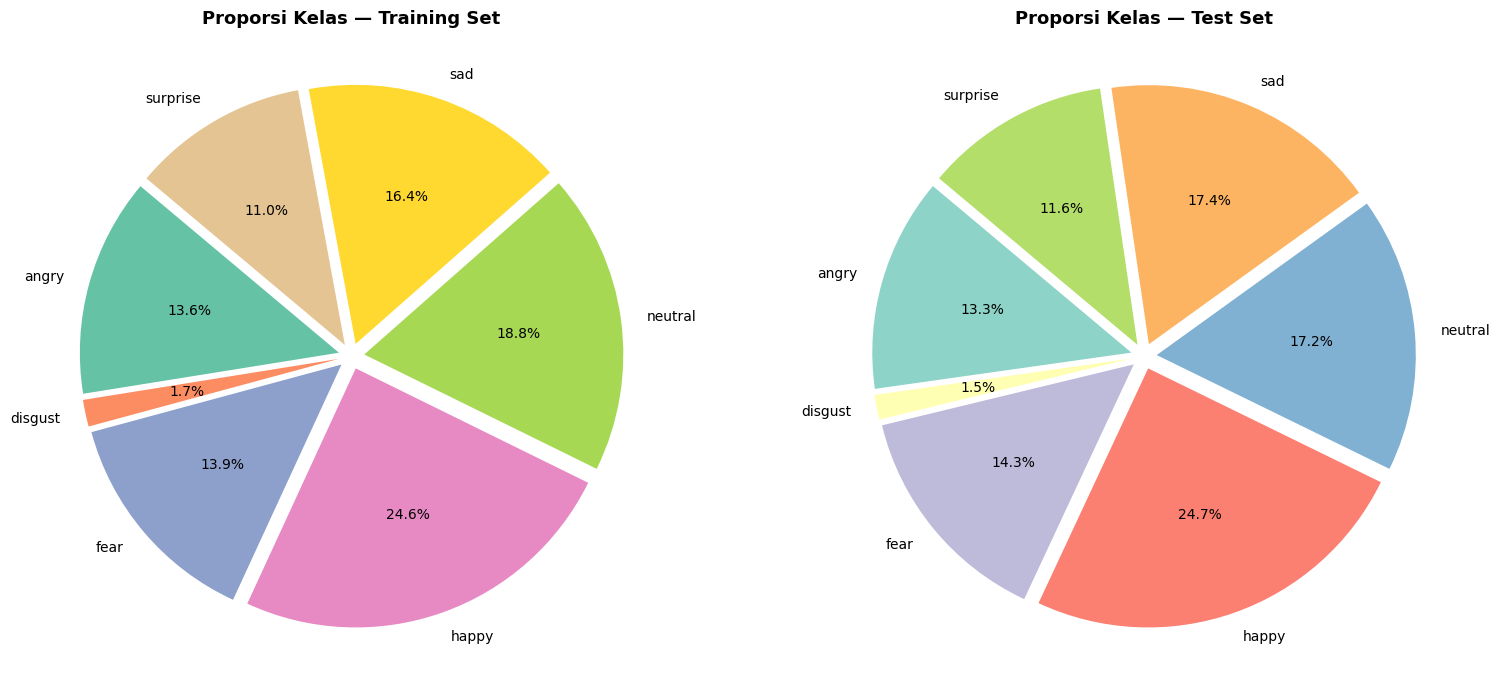

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/plots/02_class_proportion_pie.png


In [9]:
# Proporsi kelas gabungan dan test
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
counts_train = [int(np.sum(train_labels==i)) for i in range(NUM_CLASSES)]
counts_test  = [int(np.sum(test_labels==i))  for i in range(NUM_CLASSES)]
explode = [0.05] * NUM_CLASSES

axes[0].pie(counts_train, labels=EMOTIONS, autopct='%1.1f%%', startangle=140,
            colors=sns.color_palette('Set2', NUM_CLASSES), explode=explode,
            textprops={'fontsize': 10})
axes[0].set_title('Proporsi Kelas — Training Set', fontsize=13, fontweight='bold')

axes[1].pie(counts_test, labels=EMOTIONS, autopct='%1.1f%%', startangle=140,
            colors=sns.color_palette('Set3', NUM_CLASSES), explode=explode,
            textprops={'fontsize': 10})
axes[1].set_title('Proporsi Kelas — Test Set', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/02_class_proportion_pie.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {PLOT_DIR}/02_class_proportion_pie.png')

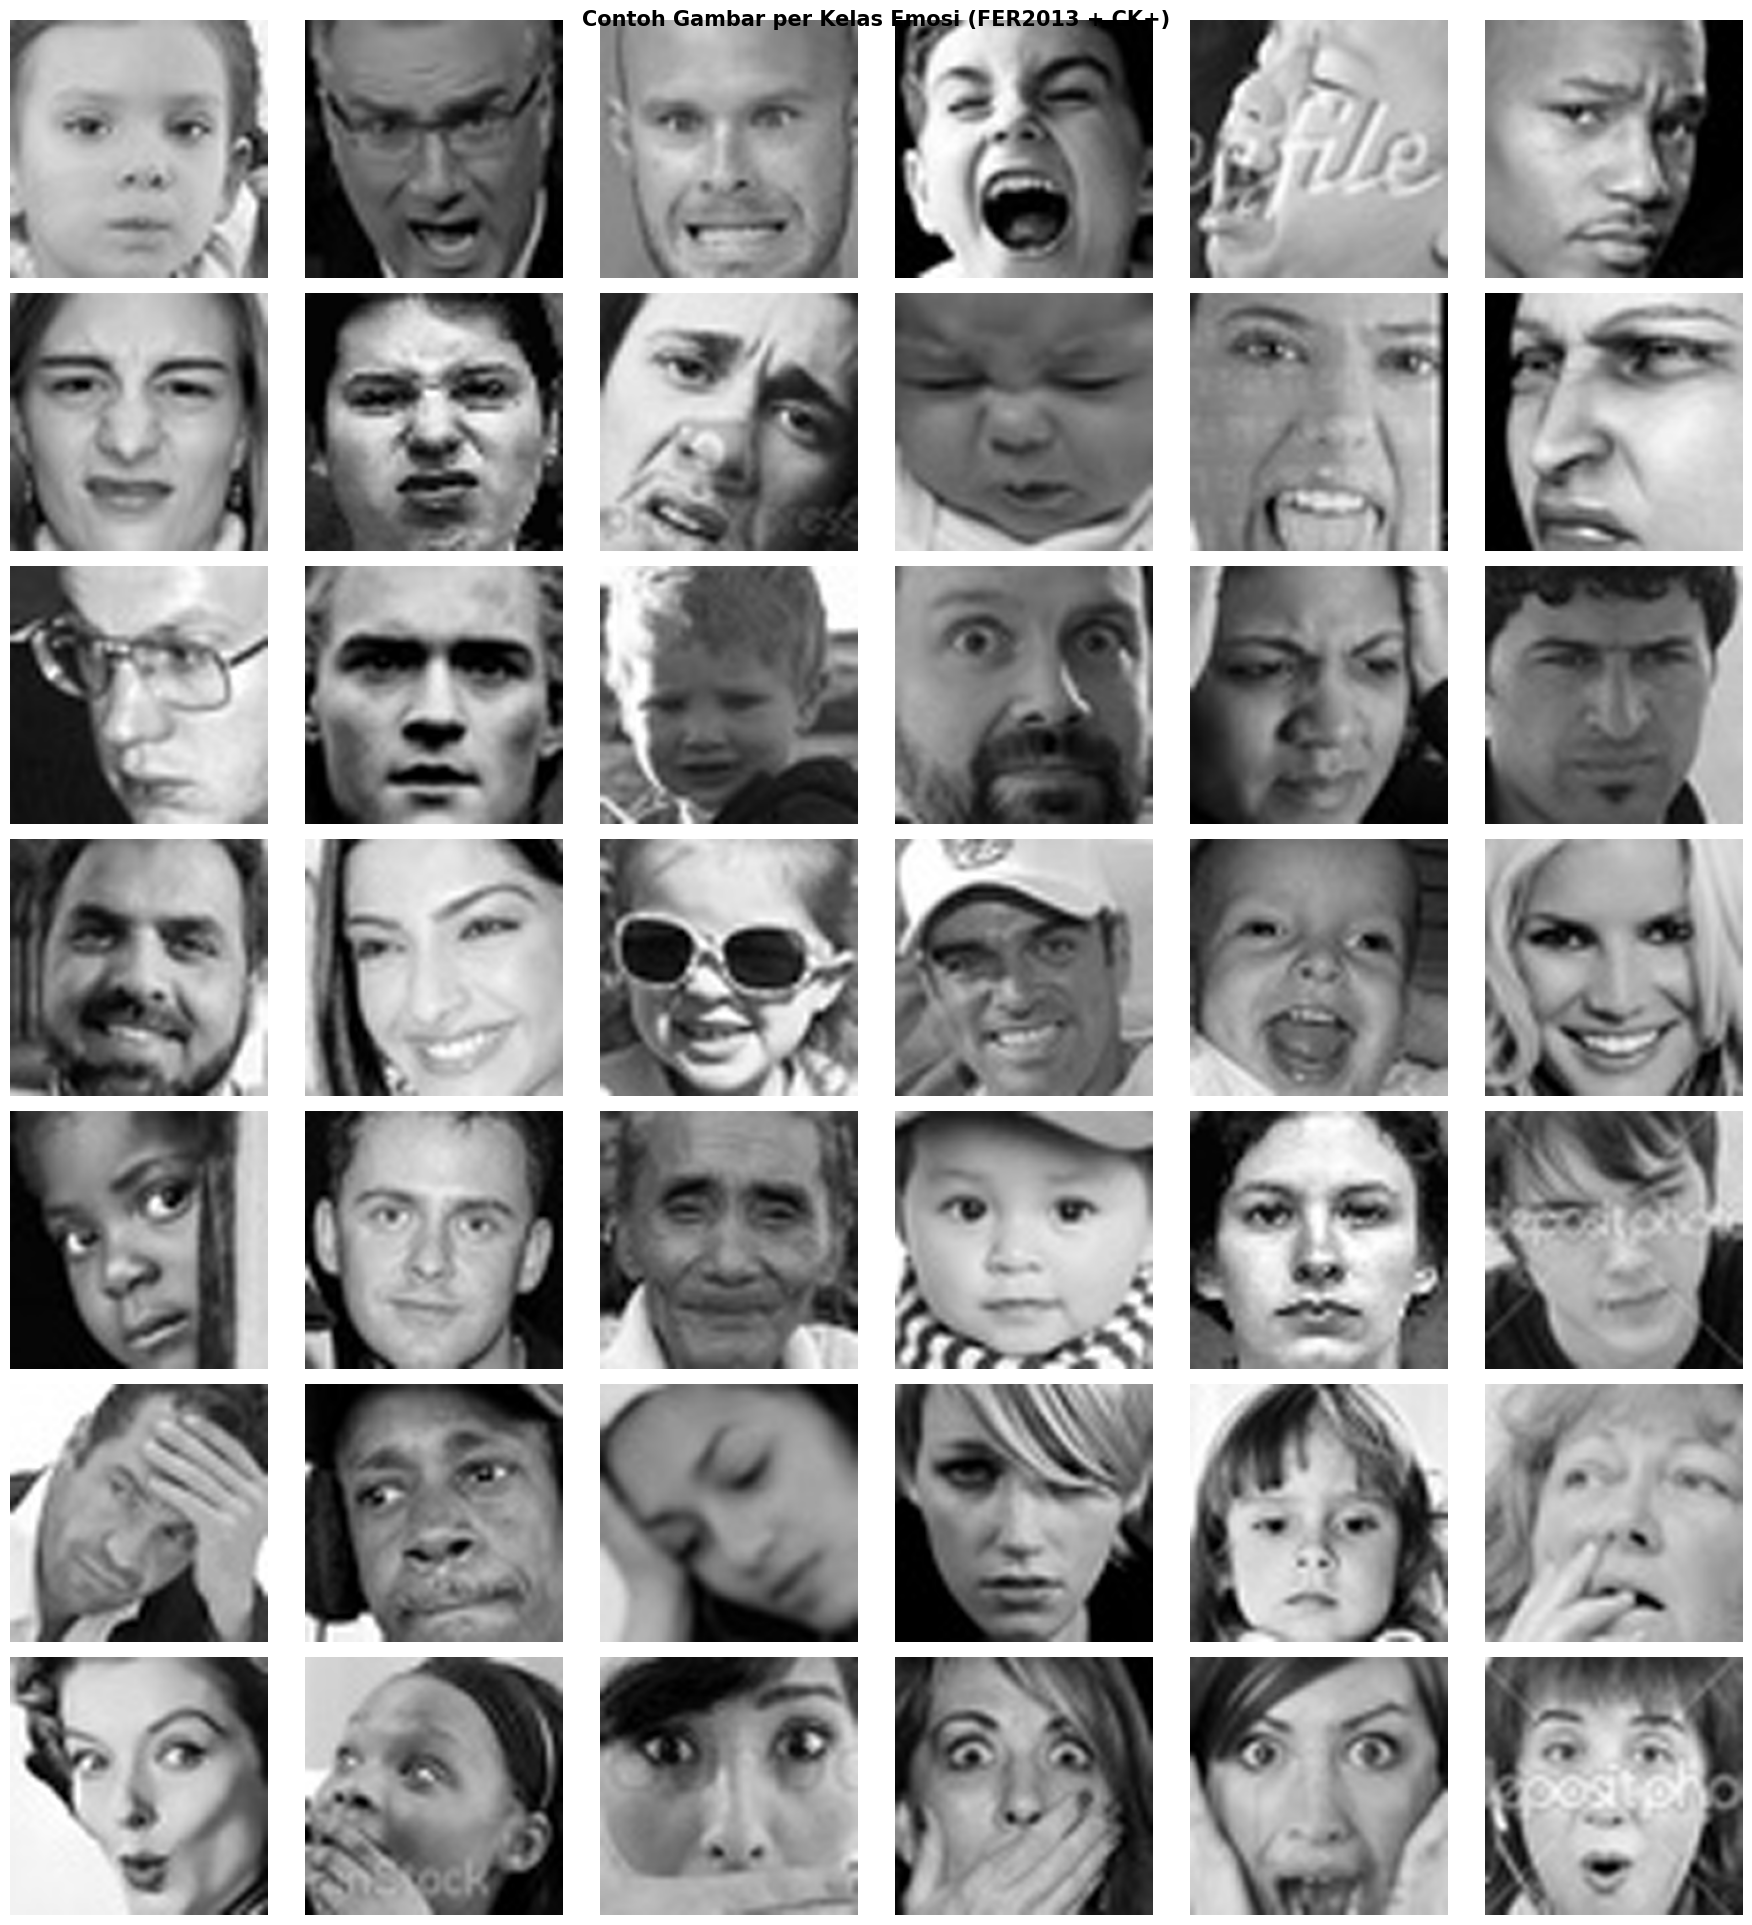

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/plots/03_sample_images_per_class.png


In [10]:
# Contoh 6 gambar per emosi — dari EDA subset
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(18, NUM_CLASSES*2.8))
fig.suptitle('Contoh Gambar per Kelas Emosi (FER2013 + CK+)', fontsize=15, fontweight='bold')

for i, emotion in enumerate(EMOTIONS):
    idx = np.where(eda_labels == i)[0]
    sample_idx = np.random.choice(idx, size=min(6, len(idx)), replace=False)
    for j, sidx in enumerate(sample_idx):
        axes[i, j].imshow(eda_images[sidx])
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_ylabel(emotion, fontsize=11, fontweight='bold',
                                  rotation=0, labelpad=55, ha='right')

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/03_sample_images_per_class.png', dpi=120, bbox_inches='tight')
plt.show()
print(f'Saved -> {PLOT_DIR}/03_sample_images_per_class.png')

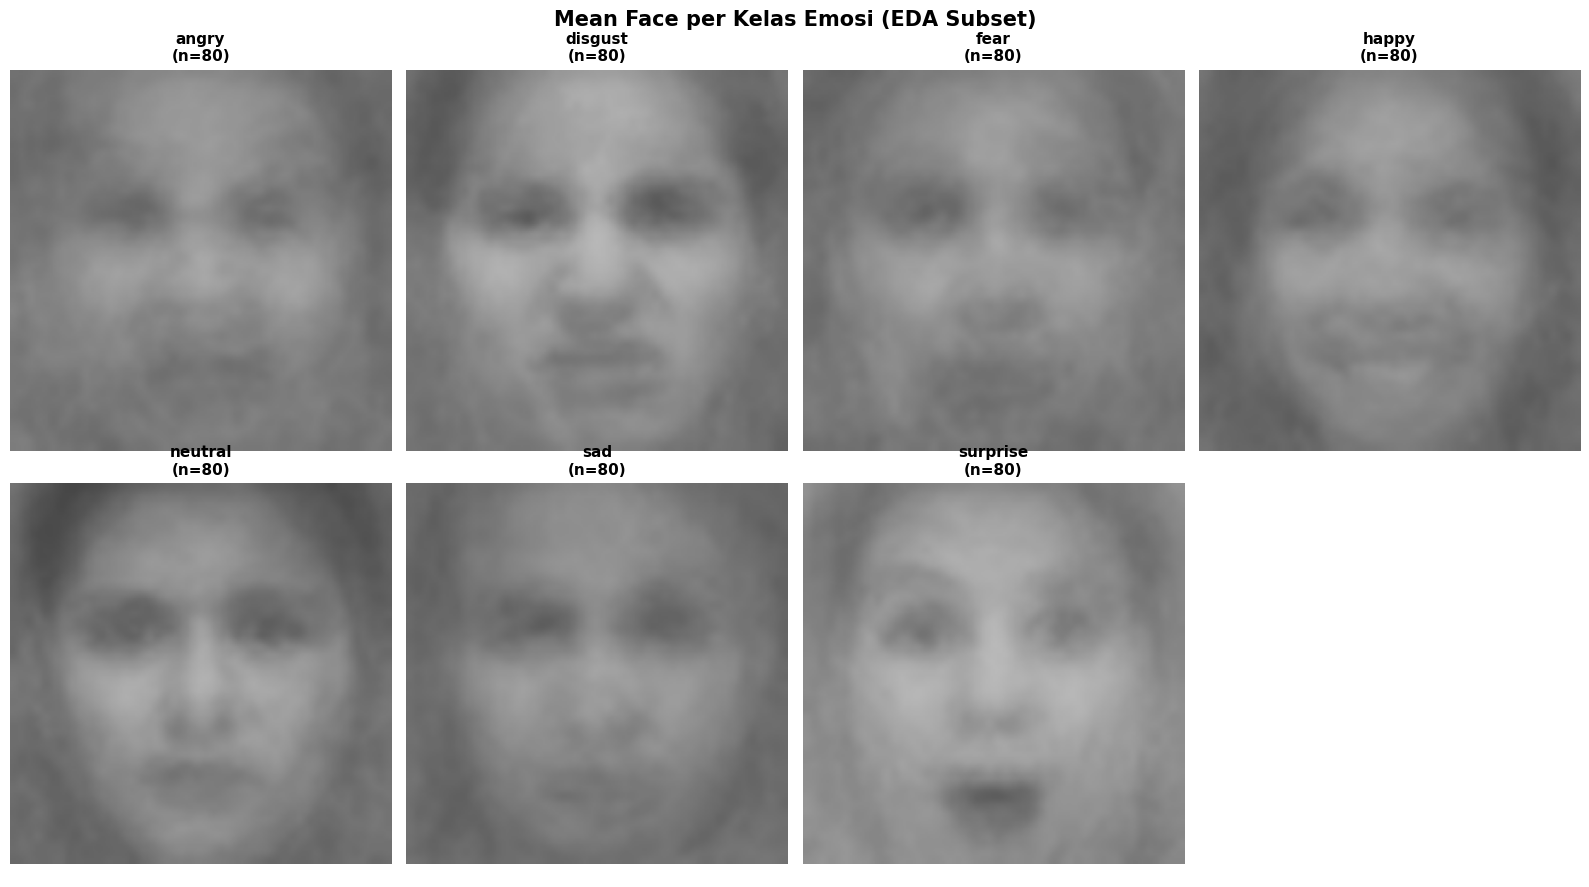

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/plots/04_mean_face_per_class.png


In [11]:
# Mean face per emosi dari EDA subset
fig, axes = plt.subplots(2, 4, figsize=(16, 9))
axes = axes.flatten()
fig.suptitle('Mean Face per Kelas Emosi (EDA Subset)', fontsize=15, fontweight='bold')

for i, emotion in enumerate(EMOTIONS):
    idx = np.where(eda_labels == i)[0]
    mean_face = eda_images[idx].mean(axis=0).astype(np.uint8)
    axes[i].imshow(mean_face)
    axes[i].set_title(f'{emotion}\n(n={len(idx)})', fontsize=11, fontweight='bold')
    axes[i].axis('off')

axes[-1].axis('off')
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/04_mean_face_per_class.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {PLOT_DIR}/04_mean_face_per_class.png')

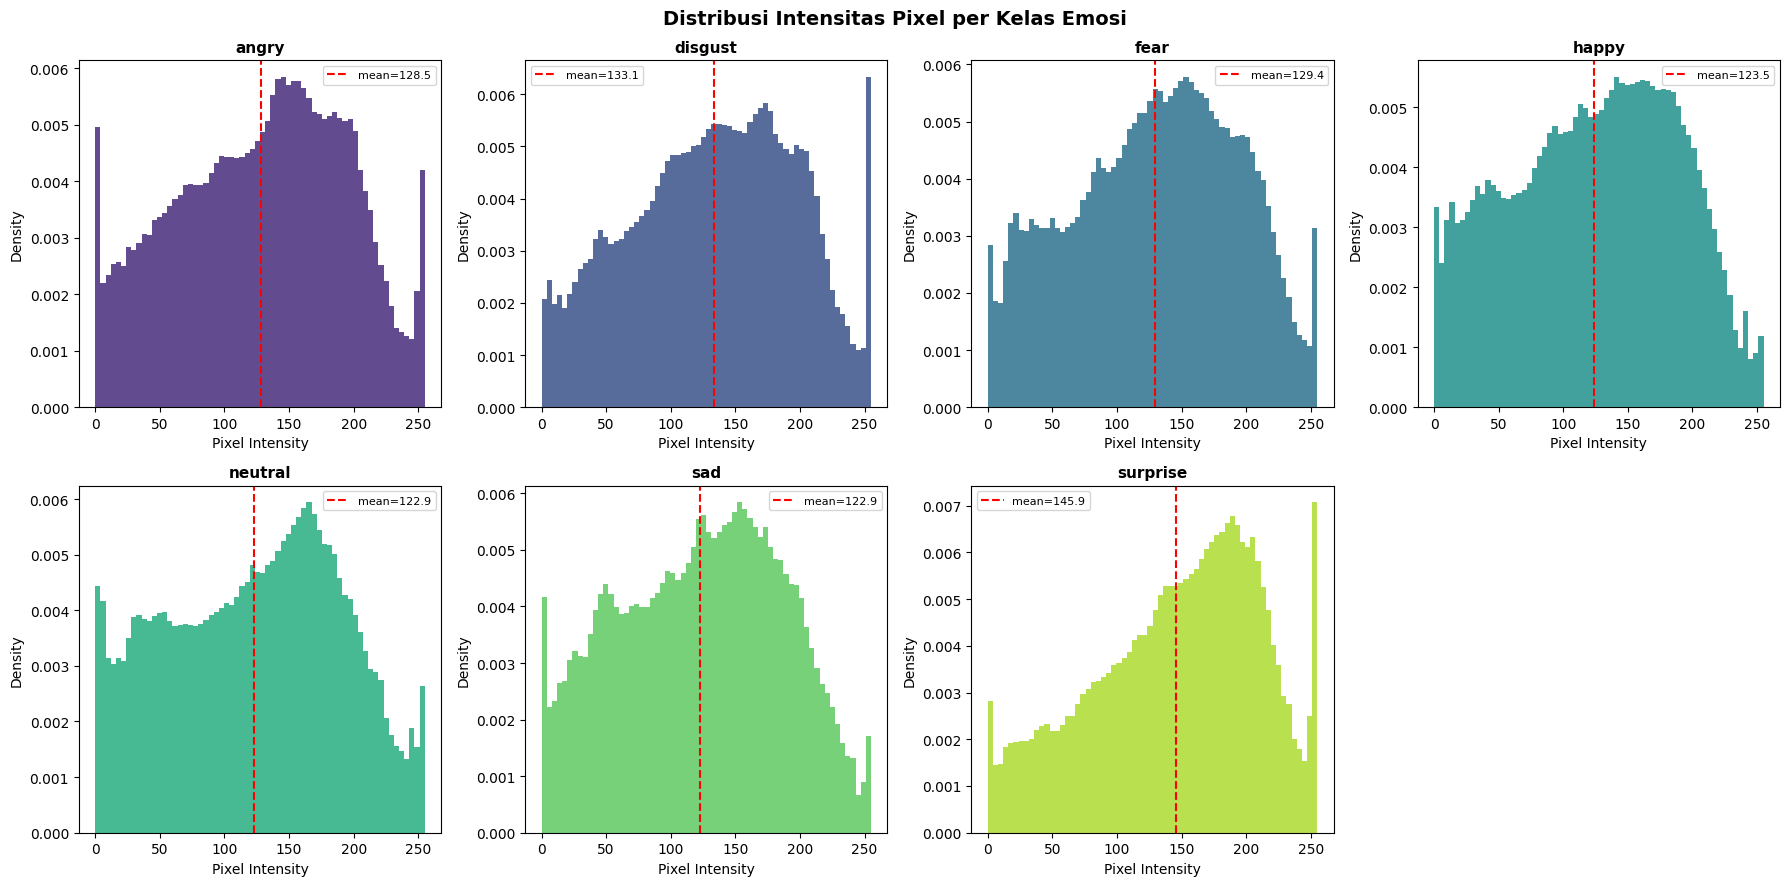

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/plots/05_pixel_intensity_distribution.png


In [12]:
# Distribusi intensitas pixel per emosi
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()
fig.suptitle('Distribusi Intensitas Pixel per Kelas Emosi', fontsize=14, fontweight='bold')

palette = sns.color_palette('viridis', NUM_CLASSES)
for i, emotion in enumerate(EMOTIONS):
    idx = np.where(eda_labels == i)[0]
    gray_vals = eda_images[idx].mean(axis=-1).flatten()
    axes[i].hist(gray_vals, bins=64, color=palette[i], edgecolor='none', alpha=0.85, density=True)
    axes[i].axvline(gray_vals.mean(), color='red', linestyle='--', linewidth=1.5,
                    label=f'mean={gray_vals.mean():.1f}')
    axes[i].set_title(emotion, fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Pixel Intensity'); axes[i].set_ylabel('Density')
    axes[i].legend(fontsize=8)

axes[-1].axis('off')
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/05_pixel_intensity_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {PLOT_DIR}/05_pixel_intensity_distribution.png')

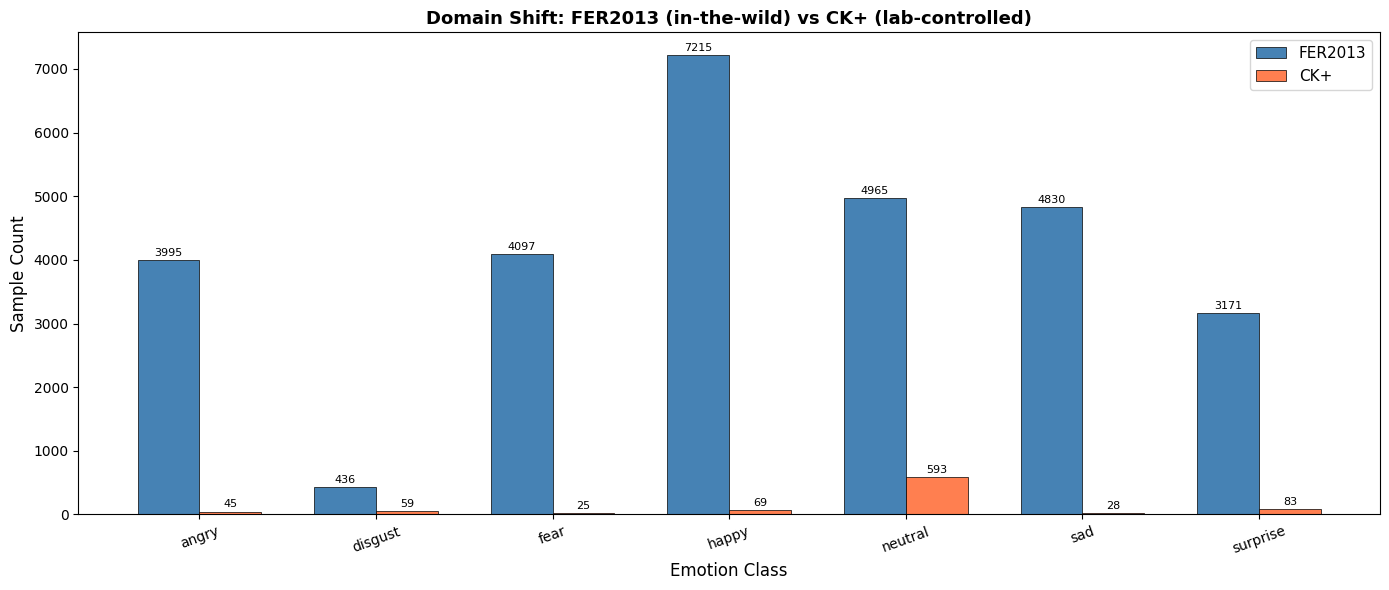

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/plots/06_fer_vs_ck_distribution.png


In [13]:
# Perbandingan distribusi FER2013 vs CK+ (domain shift analysis)
fer_only_counts = [int(np.sum(all_labels==i)) - ck_label_counts[i] for i in range(NUM_CLASSES)]

x = np.arange(NUM_CLASSES)
width = 0.35
fig, ax = plt.subplots(figsize=(14, 6))
b1 = ax.bar(x - width/2, fer_only_counts, width, label='FER2013',
            color='steelblue', edgecolor='black', lw=0.5)
b2 = ax.bar(x + width/2, ck_label_counts,  width, label='CK+',
            color='coral', edgecolor='black', lw=0.5)
ax.set_xlabel('Emotion Class', fontsize=12); ax.set_ylabel('Sample Count', fontsize=12)
ax.set_title('Domain Shift: FER2013 (in-the-wild) vs CK+ (lab-controlled)',
             fontsize=13, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(EMOTIONS, rotation=20)
ax.legend(fontsize=11)
for b in list(b1)+list(b2):
    ax.annotate(str(int(b.get_height())),
                xy=(b.get_x()+b.get_width()/2, b.get_height()),
                xytext=(0,3), textcoords='offset points', ha='center', fontsize=8)
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/06_fer_vs_ck_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {PLOT_DIR}/06_fer_vs_ck_distribution.png')

          Mean Brightness  Std Brightness  Mean Contrast  Min    Max
Emotion                                                             
angry              128.46           34.67          53.69  0.0  255.0
disgust            133.13           28.31          54.96  0.0  255.0
fear               129.42           29.87          55.02  0.0  255.0
happy              123.50           30.55          54.50  0.0  255.0
neutral            122.87           29.56          57.93  0.0  255.0
sad                122.89           32.47          52.59  0.0  255.0
surprise           145.89           33.07          52.85  0.0  255.0


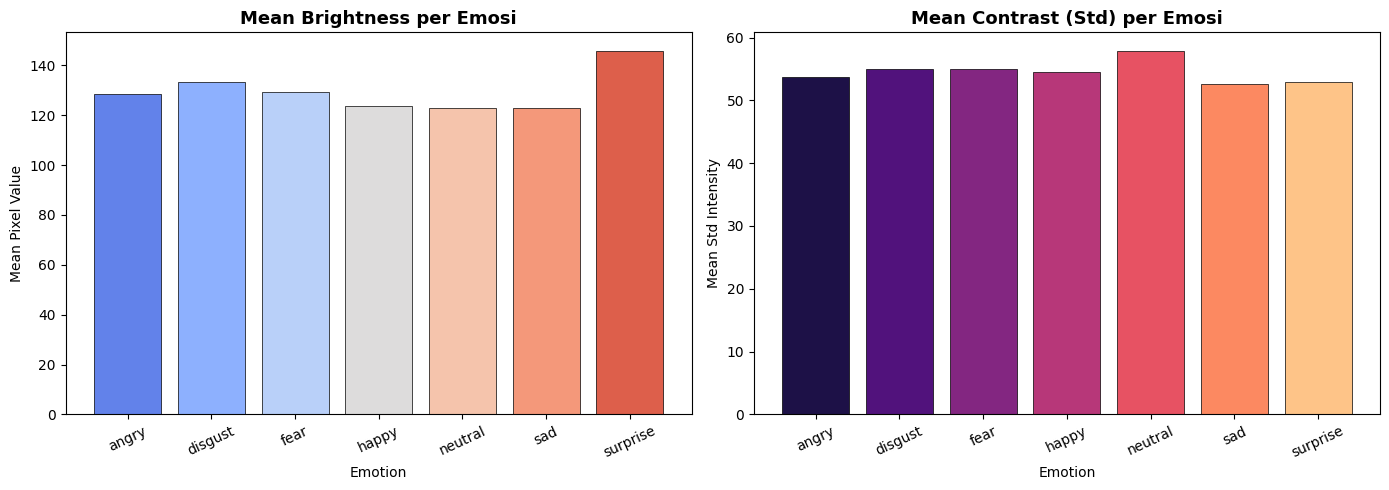

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/plots/07_brightness_contrast_stats.png


In [14]:
# Statistik brightness dan contrast per emosi
stats_list = []
for i, emotion in enumerate(EMOTIONS):
    idx = np.where(eda_labels == i)[0]
    gray = eda_images[idx].mean(axis=-1)
    stats_list.append({
        'Emotion':         emotion,
        'Mean Brightness': round(float(gray.mean()), 2),
        'Std Brightness':  round(float(gray.mean(axis=(1,2)).std()), 2),
        'Mean Contrast':   round(float(gray.std(axis=(1,2)).mean()), 2),
        'Min':             round(float(gray.min()), 2),
        'Max':             round(float(gray.max()), 2),
    })

stats_df = pd.DataFrame(stats_list).set_index('Emotion')
print(stats_df.to_string())
stats_df.to_csv(f'{OUTPUT_DIR}/eda_brightness_stats.csv')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
c1 = sns.color_palette('coolwarm', NUM_CLASSES)
c2 = sns.color_palette('magma', NUM_CLASSES)
axes[0].bar(stats_df.index, stats_df['Mean Brightness'], color=c1, edgecolor='black', lw=0.5)
axes[0].set_title('Mean Brightness per Emosi', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Emotion'); axes[0].set_ylabel('Mean Pixel Value')
axes[0].tick_params(axis='x', rotation=25)

axes[1].bar(stats_df.index, stats_df['Mean Contrast'], color=c2, edgecolor='black', lw=0.5)
axes[1].set_title('Mean Contrast (Std) per Emosi', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Emotion'); axes[1].set_ylabel('Mean Std Intensity')
axes[1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/07_brightness_contrast_stats.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {PLOT_DIR}/07_brightness_contrast_stats.png')

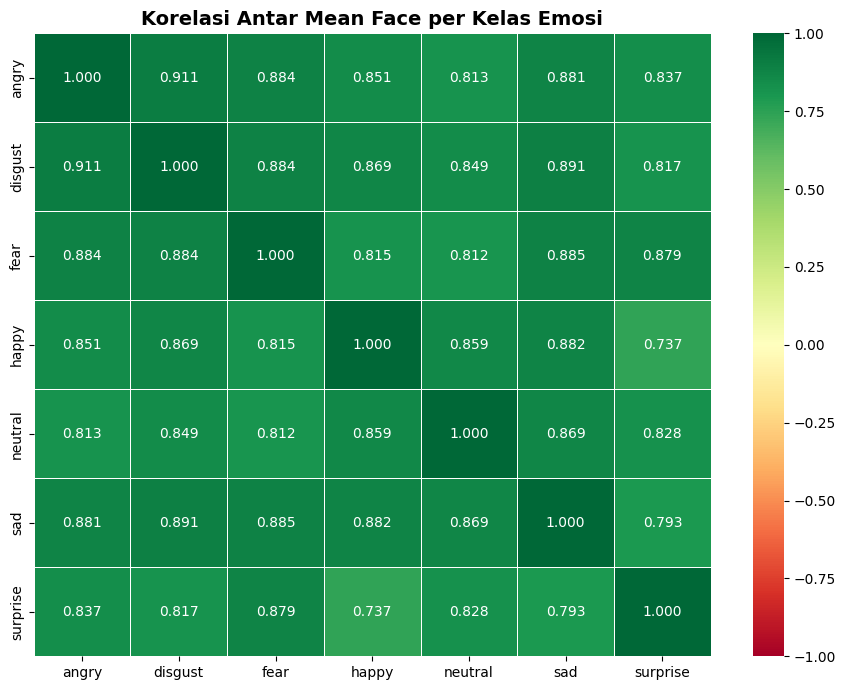

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/plots/08_inter_class_correlation.png


In [15]:
# Korelasi antar mean face per kelas
mean_faces_flat = []
for i in range(NUM_CLASSES):
    idx = np.where(eda_labels == i)[0]
    mf  = eda_images[idx].mean(axis=0).mean(axis=-1).flatten()
    mean_faces_flat.append(mf)

corr_mat = np.corrcoef(np.array(mean_faces_flat))

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_mat, annot=True, fmt='.3f',
            xticklabels=EMOTIONS, yticklabels=EMOTIONS,
            cmap='RdYlGn', vmin=-1, vmax=1, ax=ax,
            linewidths=0.5, annot_kws={'size': 10})
ax.set_title('Korelasi Antar Mean Face per Kelas Emosi', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/08_inter_class_correlation.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {PLOT_DIR}/08_inter_class_correlation.png')

Class weights:
  angry     : weight=1.0470  (n=3636)
  disgust   : weight=8.5551  (n=445)
  fear      : weight=1.0261  (n=3710)
  happy     : weight=0.5808  (n=6555)
  neutral   : weight=0.7611  (n=5002)
  sad       : weight=0.8708  (n=4372)
  surprise  : weight=1.2998  (n=2929)


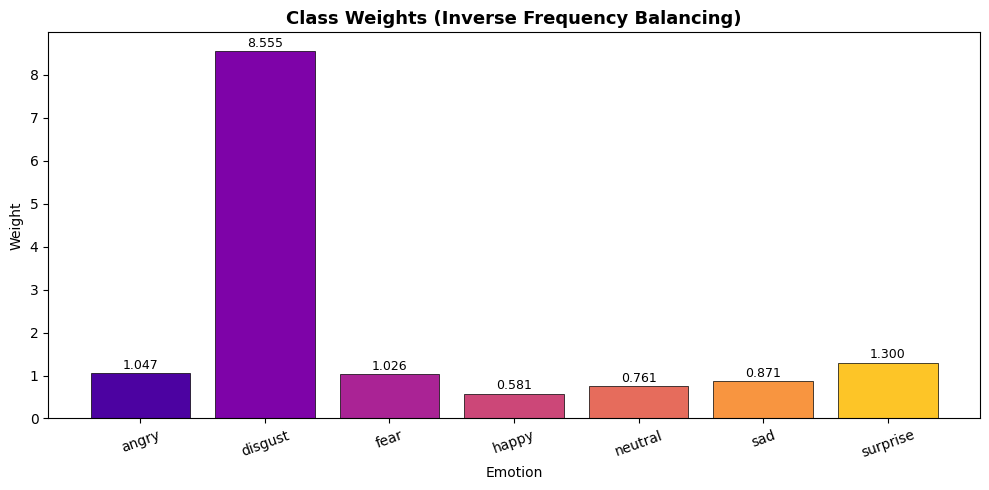

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/plots/09_class_weights.png


In [16]:
# Class weights untuk mengatasi imbalance — dihitung dari train labels
class_weights_arr = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=train_labels)
class_weight_dict = {i: float(w) for i, w in enumerate(class_weights_arr)}

print('Class weights:')
for i, emotion in enumerate(EMOTIONS):
    cnt = int(np.sum(train_labels == i))
    print(f'  {emotion:10s}: weight={class_weight_dict[i]:.4f}  (n={cnt})')

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(EMOTIONS, class_weights_arr,
       color=sns.color_palette('plasma', NUM_CLASSES), edgecolor='black', lw=0.5)
ax.set_title('Class Weights (Inverse Frequency Balancing)', fontsize=13, fontweight='bold')
ax.set_xlabel('Emotion'); ax.set_ylabel('Weight')
ax.tick_params(axis='x', rotation=20)
for i, w in enumerate(class_weights_arr):
    ax.annotate(f'{w:.3f}', xy=(i, w), xytext=(0,3),
                textcoords='offset points', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/09_class_weights.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {PLOT_DIR}/09_class_weights.png')

I0000 00:00:1776514181.012170   27879 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9837 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:01:00.0, compute capability: 8.6


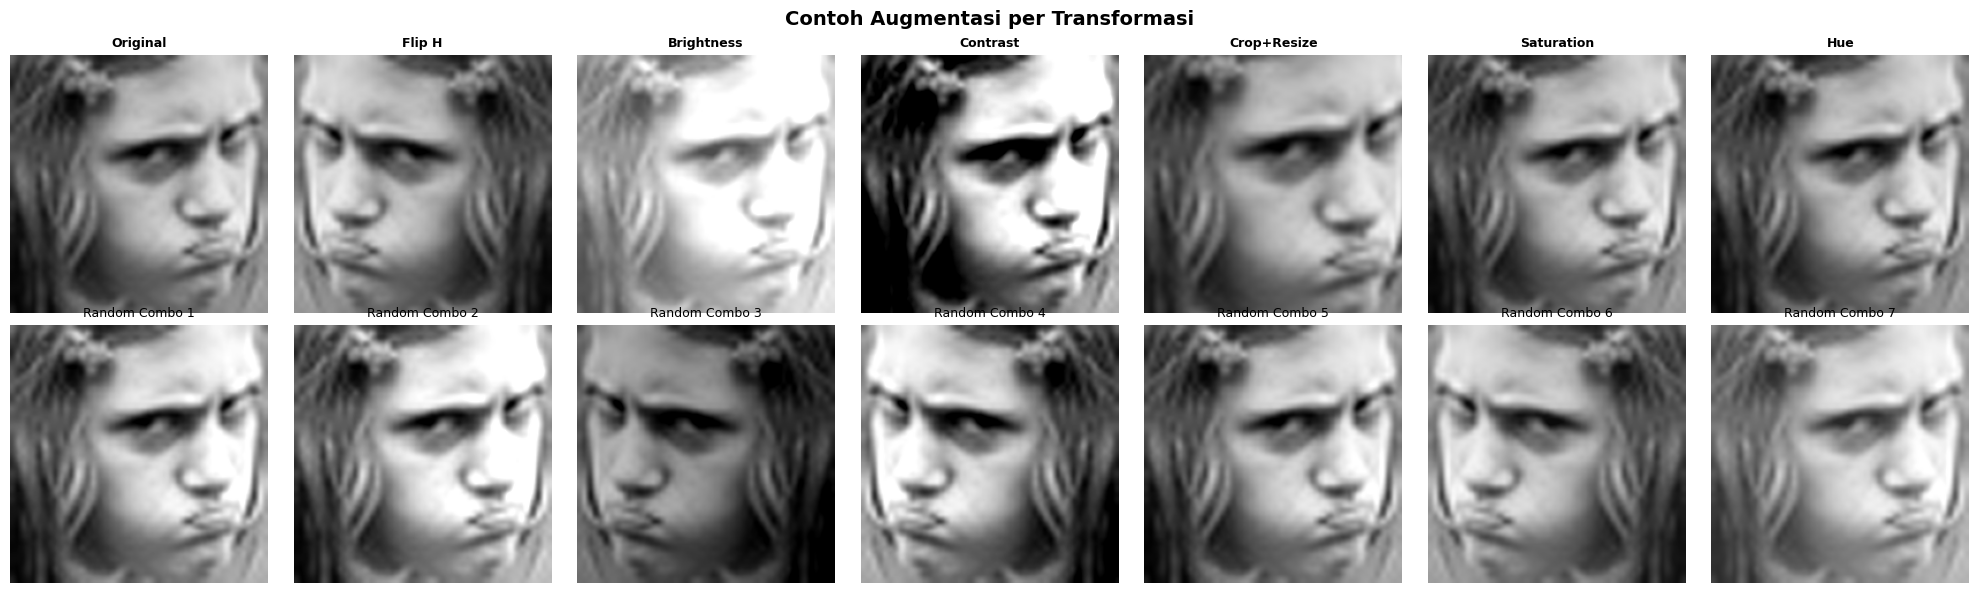

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/plots/10_augmentation_preview.png


In [17]:
# Preview augmentasi yang akan dipakai di tf.data pipeline
# Menggunakan tf.image operations yang identik dengan pipeline training
sample_img_uint8 = eda_images[0]
sample_tf = tf.cast(sample_img_uint8, tf.float32) / 255.0

fig, axes = plt.subplots(2, 7, figsize=(20, 6))
fig.suptitle('Contoh Augmentasi per Transformasi', fontsize=14, fontweight='bold')

aug_fns = [
    ('Original',    lambda x: x),
    ('Flip H',      lambda x: tf.image.flip_left_right(x)),
    ('Brightness',  lambda x: tf.image.adjust_brightness(x, 0.3)),
    ('Contrast',    lambda x: tf.image.adjust_contrast(x, 1.8)),
    ('Crop+Resize', lambda x: tf.image.resize(tf.image.crop_to_bounding_box(
                        x, 15, 15, 194, 194), [224, 224])),
    ('Saturation',  lambda x: tf.image.adjust_saturation(x, 2.0)),
    ('Hue',         lambda x: tf.image.adjust_hue(x, 0.05)),
]

for col, (name, fn) in enumerate(aug_fns):
    aug = np.clip(fn(sample_tf).numpy(), 0, 1)
    axes[0, col].imshow(aug); axes[0, col].set_title(name, fontsize=9, fontweight='bold')
    axes[0, col].axis('off')

# Baris 2: augmentasi random kombinasi
for col in range(7):
    img = sample_tf
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_brightness(img, 0.2)
    img = tf.image.random_contrast(img, 0.8, 1.3)
    aug = np.clip(img.numpy(), 0, 1)
    axes[1, col].imshow(aug)
    axes[1, col].set_title(f'Random Combo {col+1}', fontsize=9)
    axes[1, col].axis('off')

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/10_augmentation_preview.png', dpi=120, bbox_inches='tight')
plt.show()
print(f'Saved -> {PLOT_DIR}/10_augmentation_preview.png')

In [18]:
# Bebaskan EDA images dari RAM — tidak dibutuhkan lagi setelah visualisasi selesai
del eda_images, eda_labels
gc.collect()
print(f'EDA images released. RAM used: {ram_gb():.2f} GB')

EDA images released. RAM used: 7.45 GB


## 3. tf.data Pipeline — Preprocessing On-the-Fly

Kunci solusi OOM: gambar dimuat dan diproses **per batch** dari disk, bukan sekaligus ke RAM. Setiap batch di-decode, di-resize ke 224×224, lalu di-preprocess dengan VGG-16 ImageNet normalization — semuanya terjadi on-the-fly tanpa pernah menyimpan seluruh dataset float32 di memory.

**Estimasi RAM dengan pendekatan ini: ~2–4 GB** (vs ~30 GB pada pendekatan array penuh).


In [19]:
# VGG-16 preprocessing: RGB -> BGR, subtract ImageNet channel means
# Identik dengan keras.applications.vgg16.preprocess_input
VGG_MEAN = tf.constant([103.939, 116.779, 123.68], dtype=tf.float32)

def vgg_preprocess(img_float):
    img_bgr = img_float[..., ::-1]
    return img_bgr - VGG_MEAN

def load_and_preprocess(path, label):
    raw  = tf.io.read_file(path)
    img  = tf.image.decode_image(raw, channels=3, expand_animations=False)
    img  = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img  = tf.cast(img, tf.float32)
    img  = vgg_preprocess(img)
    return img, label

def augment_fn(img, label):
    # Augmentasi dalam ruang VGG-preprocessed — shift dulu ke [0,1] untuk operasi warna
    img_shifted = img + VGG_MEAN  # kembali ke BGR [0,255]
    img_shifted = img_shifted[..., ::-1]  # ke RGB
    img_shifted = img_shifted / 255.0

    img_shifted = tf.image.random_flip_left_right(img_shifted)
    img_shifted = tf.image.random_brightness(img_shifted, max_delta=0.2)
    img_shifted = tf.image.random_contrast(img_shifted, lower=0.8, upper=1.25)
    img_shifted = tf.image.random_saturation(img_shifted, lower=0.85, upper=1.15)

    # Random crop (simulate zoom-in)
    pad  = tf.random.uniform([], 0, 20, dtype=tf.int32)
    img_shifted = tf.image.resize_with_crop_or_pad(img_shifted, IMG_SIZE+pad, IMG_SIZE+pad)
    img_shifted = tf.image.random_crop(img_shifted, [IMG_SIZE, IMG_SIZE, 3])
    img_shifted = tf.clip_by_value(img_shifted, 0.0, 1.0)

    # Kembali ke VGG preprocessing
    img_out = vgg_preprocess(img_shifted * 255.0)
    return img_out, label

print('Preprocessing functions defined.')

Preprocessing functions defined.


In [20]:
# Buat tf.data.Dataset dari path arrays — gambar dimuat per batch saat training
def make_dataset(paths, labels, batch_size=32, augment=False, shuffle=False, cache=False):
    label_cat = to_categorical(labels, NUM_CLASSES).astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((paths, label_cat))
    if shuffle:
        ds = ds.shuffle(buffer_size=4096, seed=42, reshuffle_each_iteration=True)
    ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        ds = ds.map(augment_fn, num_parallel_calls=tf.data.AUTOTUNE)
    if cache:
        ds = ds.cache()  # cache ke RAM hanya jika cukup — tidak dipakai untuk train
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_paths, train_labels, batch_size=BATCH_SIZE, augment=True,  shuffle=True)
val_ds   = make_dataset(val_paths,   val_labels,   batch_size=BATCH_SIZE, augment=False, shuffle=False)
test_ds  = make_dataset(test_paths,  test_labels,  batch_size=BATCH_SIZE, augment=False, shuffle=False)

steps_per_epoch  = len(train_paths) // BATCH_SIZE
validation_steps = len(val_paths)   // BATCH_SIZE

print(f'Train steps/epoch : {steps_per_epoch}')
print(f'Validation steps  : {validation_steps}')
print(f'RAM used          : {ram_gb():.2f} GB  <- pipeline belum load apapun ke RAM')

# Verifikasi output shape satu batch
for batch_x, batch_y in train_ds.take(1):
    print(f'Batch X shape: {batch_x.shape}  dtype={batch_x.dtype}')
    print(f'Batch y shape: {batch_y.shape}  dtype={batch_y.dtype}')
    print(f'Pixel range  : [{batch_x.numpy().min():.1f}, {batch_x.numpy().max():.1f}]')

Train steps/epoch : 832
Validation steps  : 92
RAM used          : 7.53 GB  <- pipeline belum load apapun ke RAM
Batch X shape: (32, 224, 224, 3)  dtype=<dtype: 'float32'>
Batch y shape: (32, 7)  dtype=<dtype: 'float32'>
Pixel range  : [-123.7, 151.1]


## 4. Arsitektur Model — VGG-16 + SE + Spatial Attention

**Backbone**: VGG-16 pretrained ImageNet (frozen di fase awal)
**Attention head**:
- Squeeze-and-Excitation block — channel-wise recalibration (Hu et al. 2018)
- Spatial Attention — CBAM spatial branch (Woo et al. 2018)
- GlobalAveragePooling → BatchNorm → Dense(×N) → Softmax

**Progressive fine-tuning** (4 fase):
1. Head only (backbone frozen), LR=1e-3
2. + VGG block5_conv, LR=5e-5
3. + VGG block4_conv, LR=2e-5
4. Semua layer, AdamW, LR=1e-5


In [21]:
# Squeeze-and-Excitation block — Hu et al. (2018) CVPR Best Paper
def se_block(inputs, ratio=16):
    ch = inputs.shape[-1]
    x  = layers.GlobalAveragePooling2D()(inputs)
    x  = layers.Reshape((1, 1, ch))(x)
    x  = layers.Dense(max(ch // ratio, 1), activation='relu',    use_bias=False)(x)
    x  = layers.Dense(ch,                  activation='sigmoid',  use_bias=False)(x)
    return layers.Multiply()([inputs, x])

# Spatial Attention — CBAM spatial branch (Woo et al. 2018 ECCV)
def spatial_attention(inputs):
    avg_p = layers.Lambda(lambda x: tf.reduce_mean(x, axis=-1, keepdims=True))(inputs)
    max_p = layers.Lambda(lambda x: tf.reduce_max(x,  axis=-1, keepdims=True))(inputs)
    cat   = layers.Concatenate(axis=-1)([avg_p, max_p])
    attn  = layers.Conv2D(1, kernel_size=7, padding='same', activation='sigmoid')(cat)
    return layers.Multiply()([inputs, attn])

print('Attention blocks defined.')

Attention blocks defined.


In [22]:
# Factory function untuk build model — dipakai oleh HP tuner dan training final
def build_vgg16_attention(dense_units=512, dropout_rate=0.5,
                           l2_reg=1e-4, se_ratio=16,
                           num_dense_layers=2, learning_rate=1e-3):
    base = VGG16(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False

    x = se_block(base.output, ratio=se_ratio)
    x = spatial_attention(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)

    for _ in range(num_dense_layers):
        x = layers.Dense(dense_units, kernel_regularizer=regularizers.l2(l2_reg))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.Dropout(dropout_rate)(x)

    out   = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    model = Model(base.input, out)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTH),
        metrics=['accuracy']
    )
    return model

preview = build_vgg16_attention()
trainable_count   = sum(tf.size(v).numpy() for v in preview.trainable_variables)
untrainable_count = sum(tf.size(v).numpy() for v in preview.non_trainable_variables)
print(f'Total params      : {preview.count_params():,}')
print(f'Trainable (head)  : {trainable_count:,}')
print(f'Frozen (backbone) : {untrainable_count:,}')
del preview

Total params      : 15,282,602
Trainable (head)  : 564,842
Frozen (backbone) : 14,717,764


Model: "functional_1"
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 224, 224,  │      1,792 │ input_layer_1[0]… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 224, 224,  │     36,928 │ block1_conv1[0][… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_pool         │ (None, 112, 112,  │          0

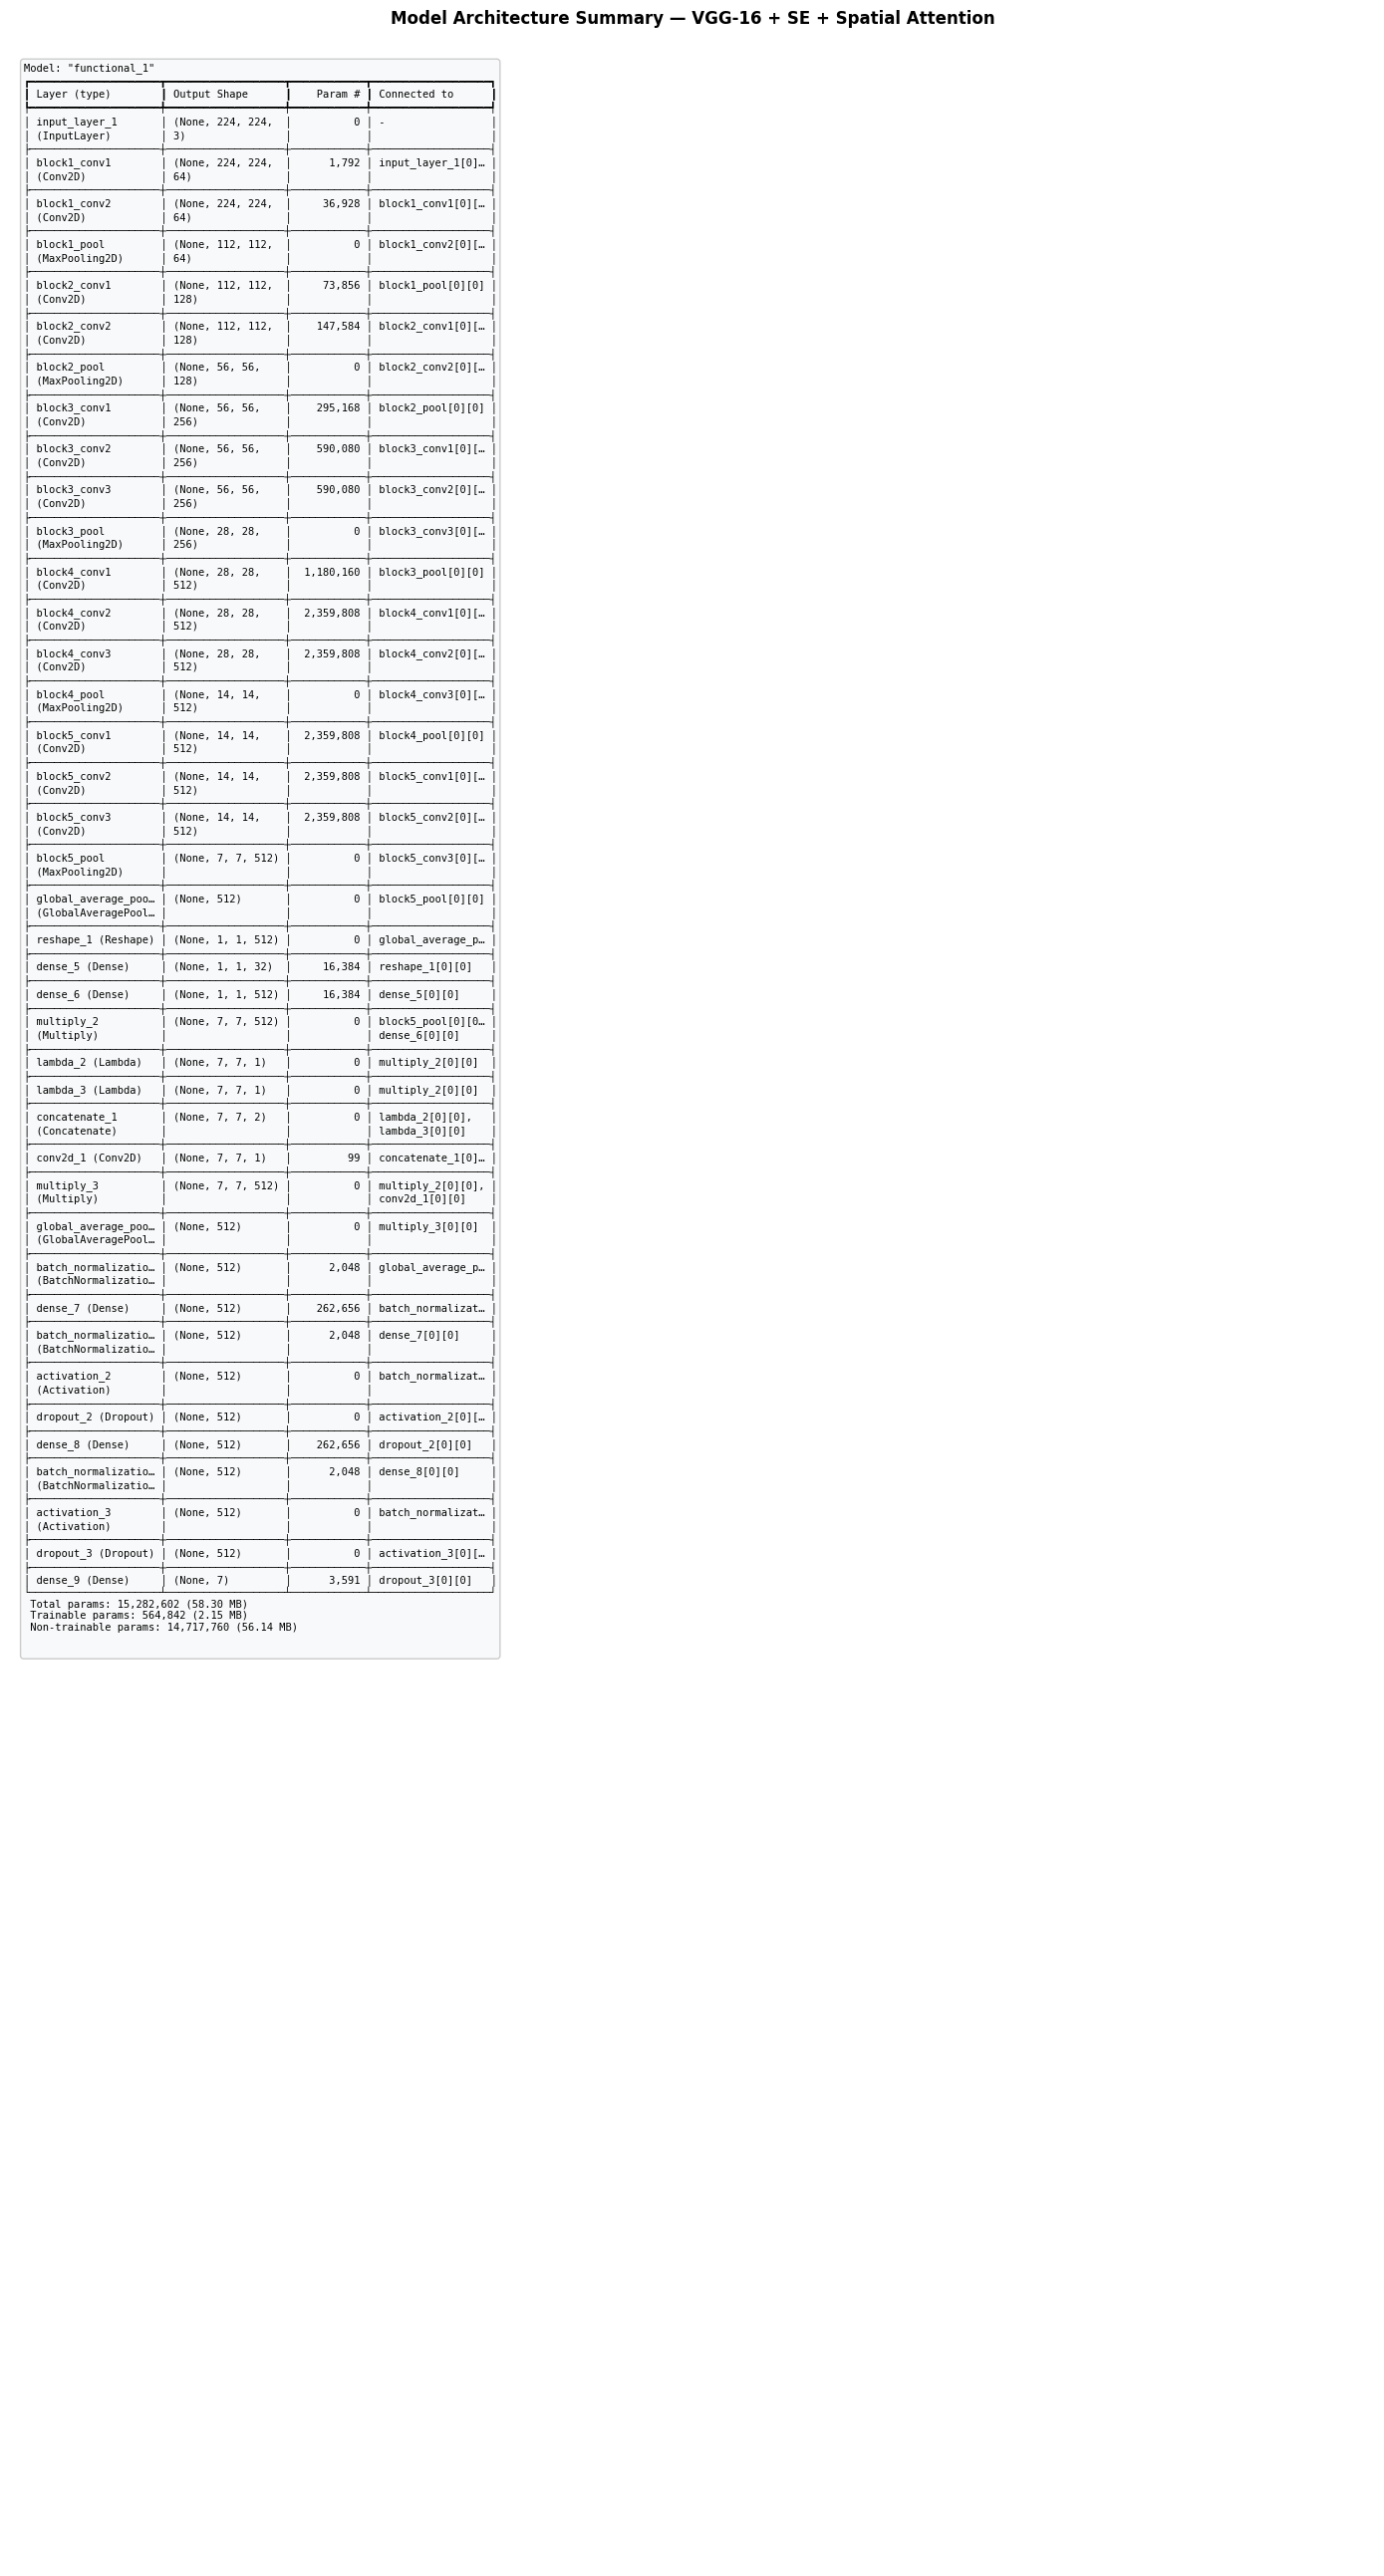

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/plots/00_model_summary.png
Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/plots/00_model_architecture.png


12664

In [23]:
# Model summary — tangkap output teks dan simpan sebagai PNG untuk laporan
import io

preview_model = build_vgg16_attention()

# Tangkap summary ke string
stream = io.StringIO()
preview_model.summary(print_fn=lambda x: stream.write(x + '\n'))
summary_str = stream.getvalue()
print(summary_str)

# Render summary teks sebagai gambar matplotlib
lines = summary_str.split('\n')
fig_h = max(8, len(lines) * 0.22)
fig, ax = plt.subplots(figsize=(14, fig_h))
ax.axis('off')
ax.text(0.01, 0.99, summary_str, transform=ax.transAxes,
        fontsize=7.5, verticalalignment='top', fontfamily='monospace',
        bbox=dict(boxstyle='round', facecolor='#f8f9fa', edgecolor='#cccccc', linewidth=1))
ax.set_title('Model Architecture Summary — VGG-16 + SE + Spatial Attention',
             fontsize=12, fontweight='bold', pad=10)
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/00_model_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {PLOT_DIR}/00_model_summary.png')

# Simpan juga visualisasi graph arsitektur jika pydot tersedia
try:
    keras.utils.plot_model(
        preview_model,
        to_file=f'{PLOT_DIR}/00_model_architecture.png',
        show_shapes=True,
        show_layer_names=True,
        show_dtype=False,
        dpi=120,
        expand_nested=False
    )
    print(f'Saved -> {PLOT_DIR}/00_model_architecture.png')
except Exception as e:
    print(f'plot_model skip: {e} (install pydot + graphviz jika diperlukan)')

del preview_model
gc.collect()

## 5. Hyperparameter Tuning — Bayesian Optimization (20 Trial)

Saya gunakan Keras Tuner BayesianOptimization untuk mencari konfigurasi optimal secara efisien. Search space:
- `dense_units`: [256, 512, 1024]
- `dropout`: [0.30 → 0.65, step 0.05]
- `l2_reg`: [1e-5, 1e-4, 5e-4, 1e-3]
- `se_ratio`: [8, 16]
- `num_dense_layers`: [1, 2, 3]
- `learning_rate`: [5e-4, 1e-3, 2e-3, 5e-3]

Setiap trial: **8 epoch** pada subset 8000 sampel — cukup untuk mengidentifikasi konfigurasi yang menjanjikan.


In [24]:
def build_model_for_tuner(hp):
    return build_vgg16_attention(
        dense_units      = hp.Choice('dense_units',       [256, 512, 1024]),
        dropout_rate     = hp.Float('dropout',   min_value=0.30, max_value=0.65, step=0.05),
        l2_reg           = hp.Choice('l2_reg',            [1e-5, 1e-4, 5e-4, 1e-3]),
        se_ratio         = hp.Choice('se_ratio',          [8, 16]),
        num_dense_layers = hp.Int('num_dense_layers',      min_value=1, max_value=3),
        learning_rate    = hp.Choice('learning_rate',     [5e-4, 1e-3, 2e-3, 5e-3])
    )

tuner = kt.BayesianOptimization(
    build_model_for_tuner,
    objective       = 'val_accuracy',
    max_trials      = 20,
    executions_per_trial = 1,
    directory       = HP_DIR,
    project_name    = 'vgg16_fer_bayesian',
    overwrite       = True
)

print(tuner.search_space_summary())

Search space summary
Default search space size: 6
dense_units (Choice)
{'default': 256, 'conditions': [], 'values': [256, 512, 1024], 'ordered': True}
dropout (Float)
{'default': 0.3, 'conditions': [], 'min_value': 0.3, 'max_value': 0.65, 'step': 0.05, 'sampling': 'linear'}
l2_reg (Choice)
{'default': 1e-05, 'conditions': [], 'values': [1e-05, 0.0001, 0.0005, 0.001], 'ordered': True}
se_ratio (Choice)
{'default': 8, 'conditions': [], 'values': [8, 16], 'ordered': True}
num_dense_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.0005, 'conditions': [], 'values': [0.0005, 0.001, 0.002, 0.005], 'ordered': True}
None


In [25]:
# Subset dataset untuk tuning — 8000 samples, shuffle tiap epoch
TUNE_N = 8000
tune_ds = (tf.data.Dataset.from_tensor_slices((train_paths[:TUNE_N],
            to_categorical(train_labels[:TUNE_N], NUM_CLASSES).astype(np.float32)))
           .shuffle(2048, seed=42)
           .map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
           .map(augment_fn,          num_parallel_calls=tf.data.AUTOTUNE)
           .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

tune_steps = TUNE_N // BATCH_SIZE

print(f'Starting Bayesian search: 20 trials x 8 epochs')
print(f'Tune subset: {TUNE_N} samples  |  {tune_steps} steps/epoch')
print(f'RAM used: {ram_gb():.2f} GB')

tuner.search(
    tune_ds,
    steps_per_epoch  = tune_steps,
    epochs           = 8,
    validation_data  = val_ds,
    validation_steps = validation_steps,
    callbacks        = [EarlyStopping(monitor='val_accuracy', patience=3,
                                      restore_best_weights=True)],
    class_weight     = class_weight_dict,
    verbose          = 1
)

print('\nHP search selesai.')
print(f'RAM used: {ram_gb():.2f} GB')

Trial 20 Complete [00h 04m 19s]
val_accuracy: 0.4663722813129425

Best val_accuracy So Far: 0.46671196818351746
Total elapsed time: 01h 20m 42s

HP search selesai.
RAM used: 10.18 GB


In [26]:
# Ambil best hyperparameters
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
best_hp_dict = {
    'dense_units':       best_hp.get('dense_units'),
    'dropout_rate':      best_hp.get('dropout'),
    'l2_reg':            best_hp.get('l2_reg'),
    'se_ratio':          best_hp.get('se_ratio'),
    'num_dense_layers':  best_hp.get('num_dense_layers'),
    'learning_rate':     best_hp.get('learning_rate'),
}

print('===== BEST HYPERPARAMETERS =====')
for k, v in best_hp_dict.items():
    print(f'  {k:20s}: {v}')

with open(f'{OUTPUT_DIR}/best_hyperparameters.json', 'w') as f:
    json.dump(best_hp_dict, f, indent=2)
print(f'\nSaved -> {OUTPUT_DIR}/best_hyperparameters.json')

===== BEST HYPERPARAMETERS =====
  dense_units         : 512
  dropout_rate        : 0.6000000000000001
  l2_reg              : 0.0005
  se_ratio            : 16
  num_dense_layers    : 1
  learning_rate       : 0.002

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/best_hyperparameters.json


trial_id  val_accuracy  dense_units  dropout  l2_reg  learning_rate  num_dense_layers
      16      0.466712          512     0.60 0.00050         0.0020                 1
      19      0.466372          512     0.35 0.00050         0.0010                 2
      08      0.464334          256     0.30 0.00050         0.0010                 2
      18      0.459239          512     0.30 0.00050         0.0010                 2
      14      0.455163         1024     0.35 0.00050         0.0005                 3
      04      0.452106          512     0.35 0.00050         0.0010                 1
      11      0.450068          256     0.45 0.00010         0.0010                 3
      09      0.448030         1024     0.35 0.00010         0.0050                 1
      03      0.445652          512     0.40 0.00010         0.0010                 2
      01      0.445312          512     0.55 0.00001         0.0010                 3
      00      0.440897          512     0.30 0.00100  

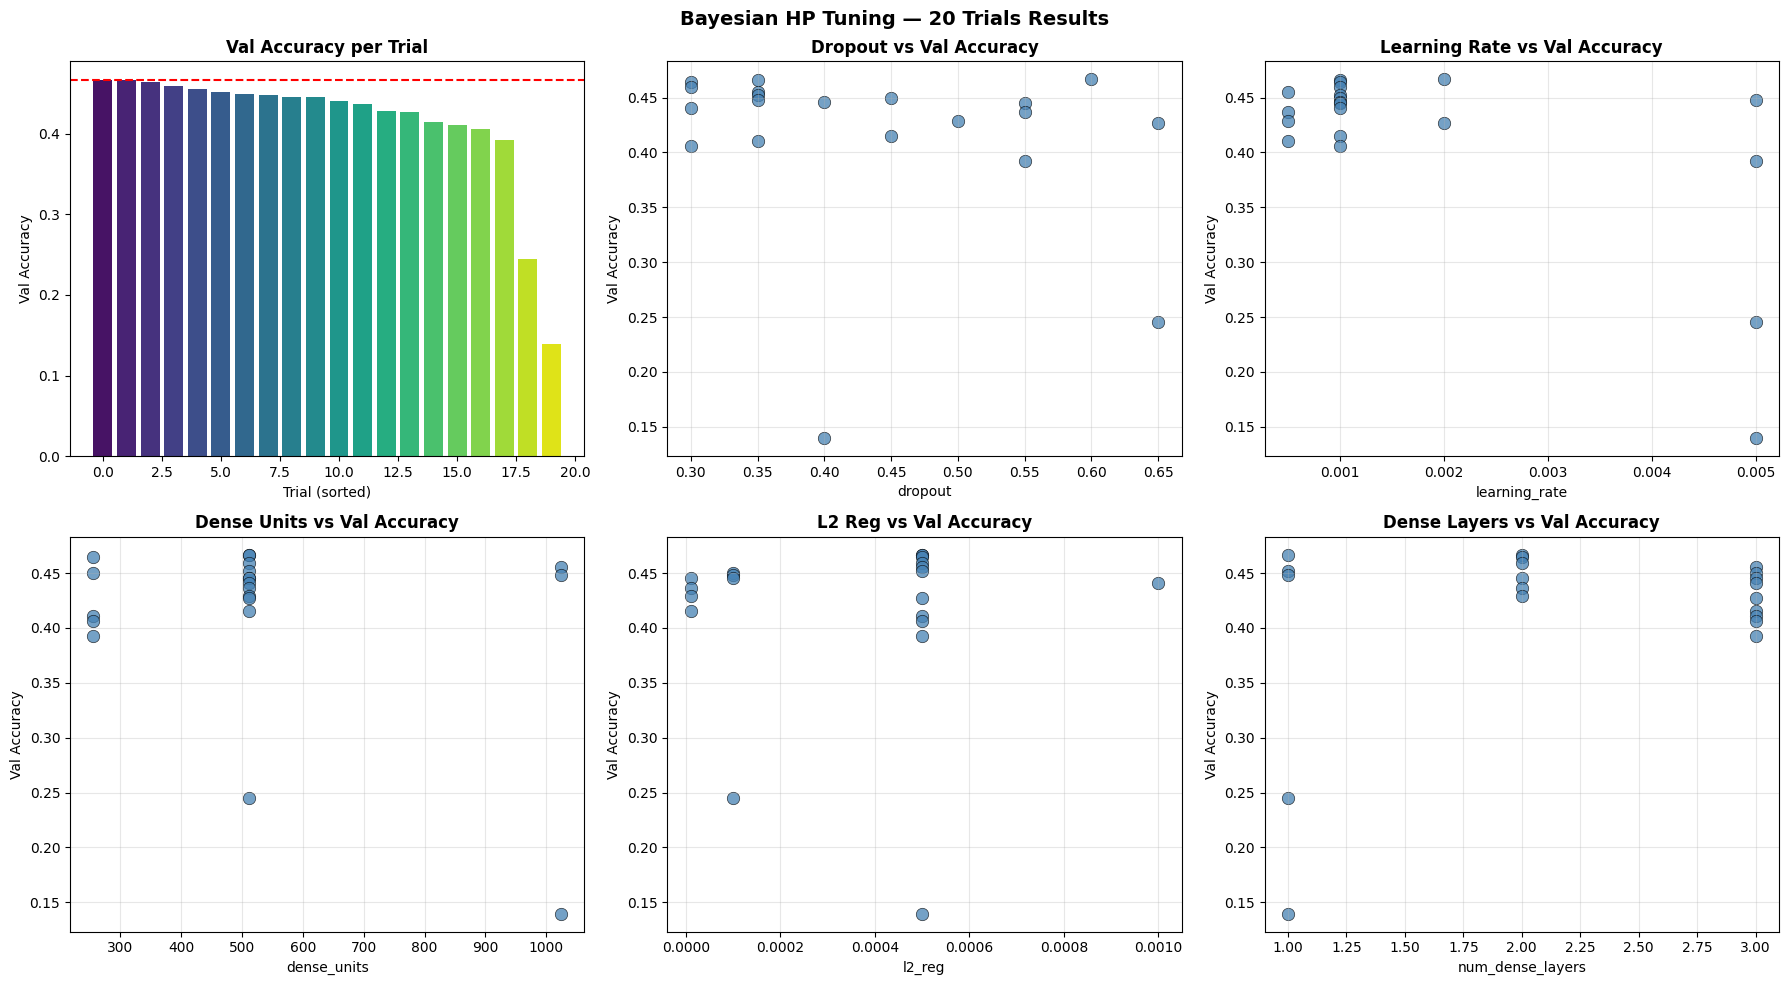

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/plots/11_hp_tuning_results.png


In [27]:
# Visualisasi hasil semua trial HP tuning
trial_results = []
for trial in tuner.oracle.trials.values():
    if trial.score is not None:
        row = {'trial_id': trial.trial_id, 'val_accuracy': trial.score}
        row.update(trial.hyperparameters.values)
        trial_results.append(row)

results_df = pd.DataFrame(trial_results).sort_values('val_accuracy', ascending=False)
print(results_df[['trial_id','val_accuracy','dense_units','dropout',
                  'l2_reg','learning_rate','num_dense_layers']].to_string(index=False))

results_df.to_csv(f'{OUTPUT_DIR}/hp_tuning_results.csv', index=False)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Bayesian HP Tuning — 20 Trials Results', fontsize=14, fontweight='bold')

axes[0,0].bar(range(len(results_df)), results_df['val_accuracy'].values,
              color=sns.color_palette('viridis', len(results_df)))
axes[0,0].set_xlabel('Trial (sorted)'); axes[0,0].set_ylabel('Val Accuracy')
axes[0,0].set_title('Val Accuracy per Trial', fontweight='bold')
axes[0,0].axhline(results_df['val_accuracy'].max(), color='red', linestyle='--', linewidth=1.5)

for ax, col, title in [
    (axes[0,1], 'dropout',          'Dropout vs Val Accuracy'),
    (axes[0,2], 'learning_rate',    'Learning Rate vs Val Accuracy'),
    (axes[1,0], 'dense_units',      'Dense Units vs Val Accuracy'),
    (axes[1,1], 'l2_reg',           'L2 Reg vs Val Accuracy'),
    (axes[1,2], 'num_dense_layers', 'Dense Layers vs Val Accuracy'),
]:
    if col in results_df.columns:
        ax.scatter(results_df[col].astype(float), results_df['val_accuracy'],
                   alpha=0.75, color='steelblue', edgecolors='black', linewidth=0.5, s=80)
        ax.set_xlabel(col); ax.set_ylabel('Val Accuracy')
        ax.set_title(title, fontweight='bold')
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/11_hp_tuning_results.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {PLOT_DIR}/11_hp_tuning_results.png')

## 6. Training — Progressive Fine-Tuning (4 Fase)

Setiap fase menggunakan dataset tf.data yang sama — tidak ada alokasi memori baru. Backbone VGG-16 di-unfreeze secara bertahap agar bobot ImageNet tidak di-overfit secara prematur.


In [28]:
# Build model final dengan best hyperparameters
model = build_vgg16_attention(**best_hp_dict)
print(f'Model built. Trainable params: {sum(tf.size(v).numpy() for v in model.trainable_variables):,}')
print(f'RAM used: {ram_gb():.2f} GB')

Model built. Trainable params: 301,162
RAM used: 10.19 GB


In [29]:
def make_callbacks(phase_name, patience_es=8, patience_lr=4):
    return [
        ModelCheckpoint(f'{MODEL_DIR}/best_{phase_name}.keras',
                        monitor='val_accuracy', save_best_only=True, mode='max', verbose=1),
        EarlyStopping(monitor='val_accuracy', patience=patience_es,
                      restore_best_weights=True, mode='max', verbose=1),
        ReduceLROnPlateau(monitor='val_accuracy', factor=0.5, patience=patience_lr,
                          min_lr=1e-7, mode='max', verbose=1),
        CSVLogger(f'{LOG_DIR}/history_{phase_name}.csv', append=False)
    ]

print('Callbacks ready.')

Callbacks ready.


In [30]:
print('=' * 60)
print('FASE 1 — Backbone Frozen (head only)')
print('=' * 60)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR_FROZEN),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTH),
    metrics=['accuracy']
)

history_p1 = model.fit(
    train_ds,
    steps_per_epoch  = steps_per_epoch,
    epochs           = EPOCHS_FROZEN,
    validation_data  = val_ds,
    validation_steps = validation_steps,
    callbacks        = make_callbacks('phase1'),
    class_weight     = class_weight_dict,
    verbose          = 1
)

print(f'Fase 1 selesai. Best val_acc: {max(history_p1.history["val_accuracy"]):.4f}')
print(f'RAM used: {ram_gb():.2f} GB')

FASE 1 — Backbone Frozen (head only)
Epoch 1/10


I0000 00:00:1776519029.913713   27960 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_358008__.97


832/832 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.2927 - loss: 2.4236
Epoch 1: val_accuracy improved from None to 0.41712, saving model to /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/best_phase1.keras

Epoch 1: finished saving model to /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/best_phase1.keras
832/832 ━━━━━━━━━━━━━━━━━━━━ 88s 102ms/step - accuracy: 0.3311 - loss: 2.2085 - val_accuracy: 0.4171 - val_loss: 1.8812 - learning_rate: 0.0010
Epoch 2/10


I0000 00:00:1776519116.624695   27957 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_358008__.97


  1/832 ━━━━━━━━━━━━━━━━━━━━ 1:44:22 8s/step - accuracy: 0.4800 - loss: 1.6416
Epoch 2: val_accuracy did not improve from 0.41712
832/832 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.4800 - loss: 1.6416 - val_accuracy: 0.4161 - val_loss: 1.8818 - learning_rate: 0.0010
Epoch 3/10
832/832 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.3862 - loss: 1.9407
Epoch 3: val_accuracy improved from 0.41712 to 0.45448, saving model to /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/best_phase1.keras

Epoch 3: finished saving model to /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/best_phase1.keras
832/832 ━━━━━━━━━━━━━━━━━━━━ 83s 99ms/step - accuracy: 0.3987 - loss: 1.9070 - val_accuracy: 0.4545 - val_loss: 1.7989 - learning_rate: 0.0010
Epoch 4/10
  1/832 ━━━━━━━━━━━━━━━━━━━━ 1:11 86ms/step - accuracy: 0.4000 - loss: 1.7349
Epoch 4: val_accuracy improved from 0.45448 to 0.45516, saving model to /media/mdprana/A02A34FD2A34D1D0/1. Skri

In [34]:
print('=' * 60)
print('FASE 2 — Unfreeze VGG Block5 Conv')
print('=' * 60)

# Backbone VGG16 proxy dari model utama (shared weights), aman untuk fine-tuning per blok
base_model = keras.Model(
    inputs=model.input,
    outputs=model.get_layer('block5_pool').output,
    name='vgg16_backbone_proxy'
)

# Freeze semua layer backbone dulu, lalu unfreeze hanya block5_conv*
base_model.trainable = True
for layer in base_model.layers:
    layer.trainable = layer.name.startswith('block5_conv')
base_model = keras.Model(
    inputs=model.input,
    outputs=model.get_layer('block5_pool').output,
    name='vgg16_backbone_proxy'
)
base_model.trainable = True
for layer in base_model.layers:
    layer.trainable = layer.name.startswith('block5_conv')

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR_FT1),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTH),
    metrics=['accuracy']
)

history_p2 = model.fit(
    train_ds,
    steps_per_epoch  = steps_per_epoch,
    epochs           = EPOCHS_FT1,
    validation_data  = val_ds,
    validation_steps = validation_steps,
    callbacks        = make_callbacks('phase2'),
    class_weight     = class_weight_dict,
    verbose          = 1
)

print(f'Fase 2 selesai. Best val_acc: {max(history_p2.history["val_accuracy"]):.4f}')

FASE 2 — Unfreeze VGG Block5 Conv
Epoch 1/15


I0000 00:00:1776521245.087931   27958 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_384529__.97


832/832 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.4661 - loss: 1.7665
Epoch 1: val_accuracy improved from None to 0.44429, saving model to /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/best_phase2.keras

Epoch 1: finished saving model to /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/best_phase2.keras
832/832 ━━━━━━━━━━━━━━━━━━━━ 107s 122ms/step - accuracy: 0.4921 - loss: 1.6972 - val_accuracy: 0.4443 - val_loss: 1.8219 - learning_rate: 5.0000e-05
Epoch 2/15


I0000 00:00:1776521350.618781   27958 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_384529__.97


  1/832 ━━━━━━━━━━━━━━━━━━━━ 57:15 4s/step - accuracy: 0.6000 - loss: 1.4427
Epoch 2: val_accuracy improved from 0.44429 to 0.44531, saving model to /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/best_phase2.keras

Epoch 2: finished saving model to /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/best_phase2.keras
832/832 ━━━━━━━━━━━━━━━━━━━━ 13s 11ms/step - accuracy: 0.6000 - loss: 1.4427 - val_accuracy: 0.4453 - val_loss: 1.8315 - learning_rate: 5.0000e-05
Epoch 3/15
832/832 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.5363 - loss: 1.5917
Epoch 3: val_accuracy improved from 0.44531 to 0.55944, saving model to /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/best_phase2.keras

Epoch 3: finished saving model to /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/best_phase2.keras
832/832 ━━━━━━━━━━━━━━━━━━━━ 100s 120ms/step - accuracy: 0.5455 - loss: 1.5687 - val_accuracy:

In [35]:
print('=' * 60)
print('FASE 3 — Unfreeze Block4 + Block5')
print('=' * 60)

for layer in base_model.layers:
    layer.trainable = (layer.name.startswith('block4_conv') or
                       layer.name.startswith('block5_conv'))

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR_FT2),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTH),
    metrics=['accuracy']
)

history_p3 = model.fit(
    train_ds,
    steps_per_epoch  = steps_per_epoch,
    epochs           = EPOCHS_FT2,
    validation_data  = val_ds,
    validation_steps = validation_steps,
    callbacks        = make_callbacks('phase3'),
    class_weight     = class_weight_dict,
    verbose          = 1
)

print(f'Fase 3 selesai. Best val_acc: {max(history_p3.history["val_accuracy"]):.4f}')

FASE 3 — Unfreeze Block4 + Block5
Epoch 1/15


I0000 00:00:1776524278.557925   27958 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_424684__.97


832/832 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - accuracy: 0.6792 - loss: 1.2628
Epoch 1: val_accuracy improved from None to 0.64334, saving model to /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/best_phase3.keras

Epoch 1: finished saving model to /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/best_phase3.keras
832/832 ━━━━━━━━━━━━━━━━━━━━ 148s 167ms/step - accuracy: 0.6855 - loss: 1.2500 - val_accuracy: 0.6433 - val_loss: 1.3716 - learning_rate: 2.0000e-05
Epoch 2/15


I0000 00:00:1776524424.211732   27959 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_424684__.97


  1/832 ━━━━━━━━━━━━━━━━━━━━ 1:20:31 6s/step - accuracy: 0.6400 - loss: 1.2572
Epoch 2: val_accuracy improved from 0.64334 to 0.64436, saving model to /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/best_phase3.keras

Epoch 2: finished saving model to /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/best_phase3.keras
832/832 ━━━━━━━━━━━━━━━━━━━━ 15s 11ms/step - accuracy: 0.6400 - loss: 1.2572 - val_accuracy: 0.6444 - val_loss: 1.3726 - learning_rate: 2.0000e-05
Epoch 3/15
832/832 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step - accuracy: 0.6980 - loss: 1.2281
Epoch 3: val_accuracy did not improve from 0.64436
832/832 ━━━━━━━━━━━━━━━━━━━━ 139s 167ms/step - accuracy: 0.7034 - loss: 1.2183 - val_accuracy: 0.6423 - val_loss: 1.3825 - learning_rate: 2.0000e-05
Epoch 4/15
  1/832 ━━━━━━━━━━━━━━━━━━━━ 1:56 140ms/step - accuracy: 0.8000 - loss: 1.0191
Epoch 4: val_accuracy did not improve from 0.64436
832/832 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accu

In [36]:
print('=' * 60)
print('FASE 4 — Full Fine-tuning (semua layer)')
print('=' * 60)

base_model.trainable = True
for layer in base_model.layers:
    layer.trainable = True

model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=LR_FT3, weight_decay=1e-5),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTH),
    metrics=['accuracy']
)

history_p4 = model.fit(
    train_ds,
    steps_per_epoch  = steps_per_epoch,
    epochs           = EPOCHS_FT3,
    validation_data  = val_ds,
    validation_steps = validation_steps,
    callbacks        = make_callbacks('phase4', patience_es=10, patience_lr=5),
    class_weight     = class_weight_dict,
    verbose          = 1
)

print(f'Fase 4 selesai. Best val_acc: {max(history_p4.history["val_accuracy"]):.4f}')
print(f'RAM used: {ram_gb():.2f} GB')

FASE 4 — Full Fine-tuning (semua layer)
Epoch 1/20


I0000 00:00:1776525417.912392   27959 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_466624__.97


832/832 ━━━━━━━━━━━━━━━━━━━━ 0s 295ms/step - accuracy: 0.7990 - loss: 1.0394
Epoch 1: val_accuracy improved from None to 0.68207, saving model to /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/best_phase4.keras

Epoch 1: finished saving model to /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/best_phase4.keras
832/832 ━━━━━━━━━━━━━━━━━━━━ 279s 307ms/step - accuracy: 0.8024 - loss: 1.0263 - val_accuracy: 0.6821 - val_loss: 1.3145 - learning_rate: 1.0000e-05
Epoch 2/20


I0000 00:00:1776525694.069833   27957 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_466624__.97


  1/832 ━━━━━━━━━━━━━━━━━━━━ 4:03:01 18s/step - accuracy: 0.8800 - loss: 0.9620
Epoch 2: val_accuracy did not improve from 0.68207
832/832 ━━━━━━━━━━━━━━━━━━━━ 26s 10ms/step - accuracy: 0.8800 - loss: 0.9620 - val_accuracy: 0.6793 - val_loss: 1.3157 - learning_rate: 1.0000e-05
Epoch 3/20
832/832 ━━━━━━━━━━━━━━━━━━━━ 0s 299ms/step - accuracy: 0.8038 - loss: 1.0185
Epoch 3: val_accuracy did not improve from 0.68207
832/832 ━━━━━━━━━━━━━━━━━━━━ 258s 310ms/step - accuracy: 0.8132 - loss: 1.0045 - val_accuracy: 0.6685 - val_loss: 1.3282 - learning_rate: 1.0000e-05
Epoch 4/20
  1/832 ━━━━━━━━━━━━━━━━━━━━ 3:45 272ms/step - accuracy: 0.7600 - loss: 1.0709
Epoch 4: val_accuracy did not improve from 0.68207
832/832 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.7600 - loss: 1.0709 - val_accuracy: 0.6658 - val_loss: 1.3316 - learning_rate: 1.0000e-05
Epoch 5/20
832/832 ━━━━━━━━━━━━━━━━━━━━ 0s 316ms/step - accuracy: 0.8202 - loss: 0.9928
Epoch 5: val_accuracy did not improve from 0.68207
832/832 

In [37]:
# Gabungkan history 4 fase
def merge_histories(*hs):
    merged = {'accuracy':[], 'val_accuracy':[], 'loss':[], 'val_loss':[]}
    for h in hs:
        for k in merged:
            merged[k].extend(h.history.get(k, []))
    return merged

all_history = merge_histories(history_p1, history_p2, history_p3, history_p4)
phase_boundaries = [EPOCHS_FROZEN,
                    EPOCHS_FROZEN + EPOCHS_FT1,
                    EPOCHS_FROZEN + EPOCHS_FT1 + EPOCHS_FT2]

print(f'Total epochs trained : {len(all_history["accuracy"])}')
print(f'Best val_accuracy    : {max(all_history["val_accuracy"]):.4f}')

Total epochs trained : 60
Best val_accuracy    : 0.6943


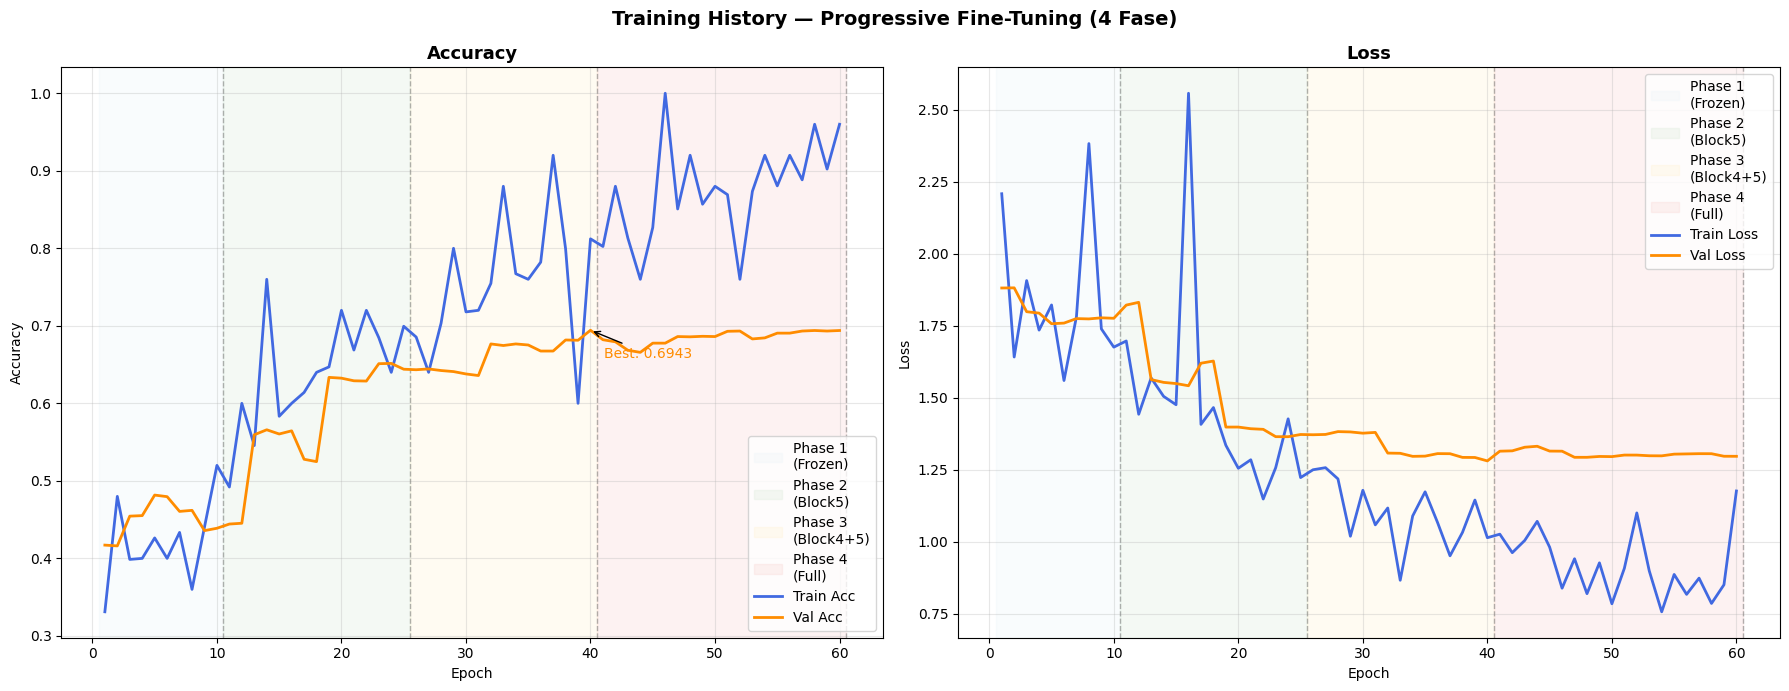

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/plots/12_training_history.png


In [38]:
# Plot history training semua fase
epochs_total = range(1, len(all_history['accuracy']) + 1)
phase_labels = ['Phase 1\n(Frozen)', 'Phase 2\n(Block5)', 'Phase 3\n(Block4+5)', 'Phase 4\n(Full)']
colors_phase = ['#E8F4F8', '#D5E8D4', '#FFF2CC', '#F8CECC']

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Training History — Progressive Fine-Tuning (4 Fase)', fontsize=14, fontweight='bold')

for ax in axes:
    prev = 0
    for boundary, label, color in zip(phase_boundaries + [len(all_history['accuracy'])],
                                       phase_labels, colors_phase):
        ax.axvspan(prev+0.5, boundary+0.5, alpha=0.25, color=color, label=label)
        ax.axvline(boundary+0.5, color='gray', linestyle='--', linewidth=1, alpha=0.6)
        prev = boundary

axes[0].plot(epochs_total, all_history['accuracy'],     label='Train Acc', color='royalblue',  lw=2)
axes[0].plot(epochs_total, all_history['val_accuracy'], label='Val Acc',   color='darkorange', lw=2)
best_val_ep = all_history['val_accuracy'].index(max(all_history['val_accuracy'])) + 1
best_val    = max(all_history['val_accuracy'])
axes[0].annotate(f'Best: {best_val:.4f}', xy=(best_val_ep, best_val),
                 xytext=(10, -20), textcoords='offset points',
                 arrowprops=dict(arrowstyle='->', color='black'), fontsize=10, color='darkorange')
axes[0].set_title('Accuracy', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
axes[0].legend(loc='lower right'); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_total, all_history['loss'],     label='Train Loss', color='royalblue',  lw=2)
axes[1].plot(epochs_total, all_history['val_loss'], label='Val Loss',   color='darkorange', lw=2)
axes[1].set_title('Loss', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
axes[1].legend(loc='upper right'); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/12_training_history.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {PLOT_DIR}/12_training_history.png')

## 7. Evaluasi Model

Saya evaluasi pada FER2013 test set murni. Setiap checkpoint dari 4 fase di-load dan di-benchmark — model dengan test accuracy tertinggi yang dipakai untuk evaluasi lanjutan.

In [44]:
# Benchmark semua checkpoint, pilih yang terbaik
checkpoint_scores = {}
for phase in ['phase1', 'phase2', 'phase3', 'phase4']:
    ckpt = f'{MODEL_DIR}/best_{phase}.keras'
    if not os.path.exists(ckpt):
        continue
    try:
        m = keras.models.load_model(ckpt, compile=False, safe_mode=False)
    except TypeError:
        # Kompatibilitas versi Keras/tf.keras yang belum support safe_mode
        try:
            keras.config.enable_unsafe_deserialization()
        except Exception:
            try:
                tf.keras.config.enable_unsafe_deserialization()
            except Exception:
                pass
        m = keras.models.load_model(ckpt, compile=False)
    except Exception as e:
        print(f'{phase}: gagal load checkpoint ({e})')
        continue
    m.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])
    _, acc = m.evaluate(test_ds, steps=len(test_paths)//BATCH_SIZE + 1, verbose=0)
    checkpoint_scores[phase] = {'model': m, 'acc': float(acc)}
    print(f'{phase}: test_acc = {acc:.4f}')
    del m
    gc.collect()

if not checkpoint_scores:
    # Fallback: jika file checkpoint tidak ada/tidak valid, pakai model in-memory (jika tersedia)
    available_files = sorted([
        f for f in os.listdir(MODEL_DIR)
        if f.endswith(('.keras', '.h5'))
    ])

    if 'model' in globals() and isinstance(model, keras.Model):
        print('Tidak ada checkpoint valid. Fallback ke model in-memory saat ini.')
        _, acc = model.evaluate(test_ds, steps=len(test_paths)//BATCH_SIZE + 1, verbose=0)
        checkpoint_scores['in_memory'] = {'acc': float(acc)}
    else:
        raise ValueError(
            f"Tidak ada checkpoint valid di {MODEL_DIR}. "
            f"File model yang terdeteksi: {available_files if available_files else 'tidak ada'}"
        )

best_phase = max(checkpoint_scores, key=lambda p: checkpoint_scores[p]['acc'])

# Lepas referensi model dari dict (agar RAM lebih ringan), simpan hanya skor
for p in checkpoint_scores:
    checkpoint_scores[p].pop('model', None)
gc.collect()

# Antisipasi error safe_mode saat load ulang model terbaik di baris bawah
try:
    keras.config.enable_unsafe_deserialization()
except Exception:
    try:
        tf.keras.config.enable_unsafe_deserialization()
    except Exception:
        pass

best_phase = max(checkpoint_scores, key=lambda p: checkpoint_scores[p]['acc'])
if best_phase == 'in_memory':
    if 'model' not in globals() or not isinstance(model, keras.Model):
        raise ValueError('best_phase=in_memory, tetapi objek model in-memory tidak tersedia.')
    print('Menggunakan model in-memory (tanpa load dari file).')
else:
    best_ckpt = f'{MODEL_DIR}/best_{best_phase}.keras'
    if not os.path.exists(best_ckpt):
        raise ValueError(f'Checkpoint terbaik tidak ditemukan: {best_ckpt}')
    try:
        model = keras.models.load_model(best_ckpt, compile=False, safe_mode=False)
    except TypeError:
        model = keras.models.load_model(best_ckpt, compile=False)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
print(f'\nModel terbaik: {best_phase}  acc={checkpoint_scores[best_phase]["acc"]:.4f}')
print(f'RAM used: {ram_gb():.2f} GB')

phase1: gagal load checkpoint (Exception encountered when calling Lambda.call().

We could not automatically infer the shape of the Lambda's output. Please specify the `output_shape` argument for this Lambda layer.

Arguments received by Lambda.call():
  • args=('<KerasTensor shape=(None, 7, 7, 512), dtype=float32, sparse=False, ragged=False, name=keras_tensor_767>',)
  • kwargs={'mask': 'None'})
phase2: gagal load checkpoint (Exception encountered when calling Lambda.call().

We could not automatically infer the shape of the Lambda's output. Please specify the `output_shape` argument for this Lambda layer.

Arguments received by Lambda.call():
  • args=('<KerasTensor shape=(None, 7, 7, 512), dtype=float32, sparse=False, ragged=False, name=keras_tensor_816>',)
  • kwargs={'mask': 'None'})
phase3: gagal load checkpoint (Exception encountered when calling Lambda.call().

We could not automatically infer the shape of the Lambda's output. Please specify the `output_shape` argument for this

In [45]:
# Ambil prediksi probabilitas untuk seluruh test set
y_pred_prob = model.predict(test_ds, steps=len(test_paths)//BATCH_SIZE+1, verbose=1)
y_pred_prob = y_pred_prob[:len(test_paths)]  # trim padding batch terakhir
y_pred      = np.argmax(y_pred_prob, axis=1)
y_true      = test_labels

test_acc = np.mean(y_pred == y_true)
print(f'\nTest Accuracy (standard): {test_acc:.4f} ({test_acc*100:.2f}%)')

report = classification_report(y_true, y_pred, target_names=EMOTIONS, digits=4)
print('\nClassification Report:')
print(report)

with open(f'{OUTPUT_DIR}/classification_report.txt', 'w') as f:
    f.write(f'Test Accuracy: {test_acc:.4f}\n\n')
    f.write(report)
print(f'Saved -> {OUTPUT_DIR}/classification_report.txt')

225/225 ━━━━━━━━━━━━━━━━━━━━ 24s 101ms/step

Test Accuracy (standard): 0.6833 (68.33%)

Classification Report:
              precision    recall  f1-score   support

       angry     0.6041    0.6086    0.6063       958
     disgust     0.6491    0.6667    0.6578       111
        fear     0.5763    0.4980    0.5343      1024
       happy     0.8673    0.8692    0.8682      1774
     neutral     0.5903    0.6894    0.6360      1233
         sad     0.5805    0.5349    0.5568      1247
    surprise     0.8017    0.8171    0.8093       831

    accuracy                         0.6833      7178
   macro avg     0.6670    0.6691    0.6670      7178
weighted avg     0.6823    0.6833    0.6816      7178

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/classification_report.txt


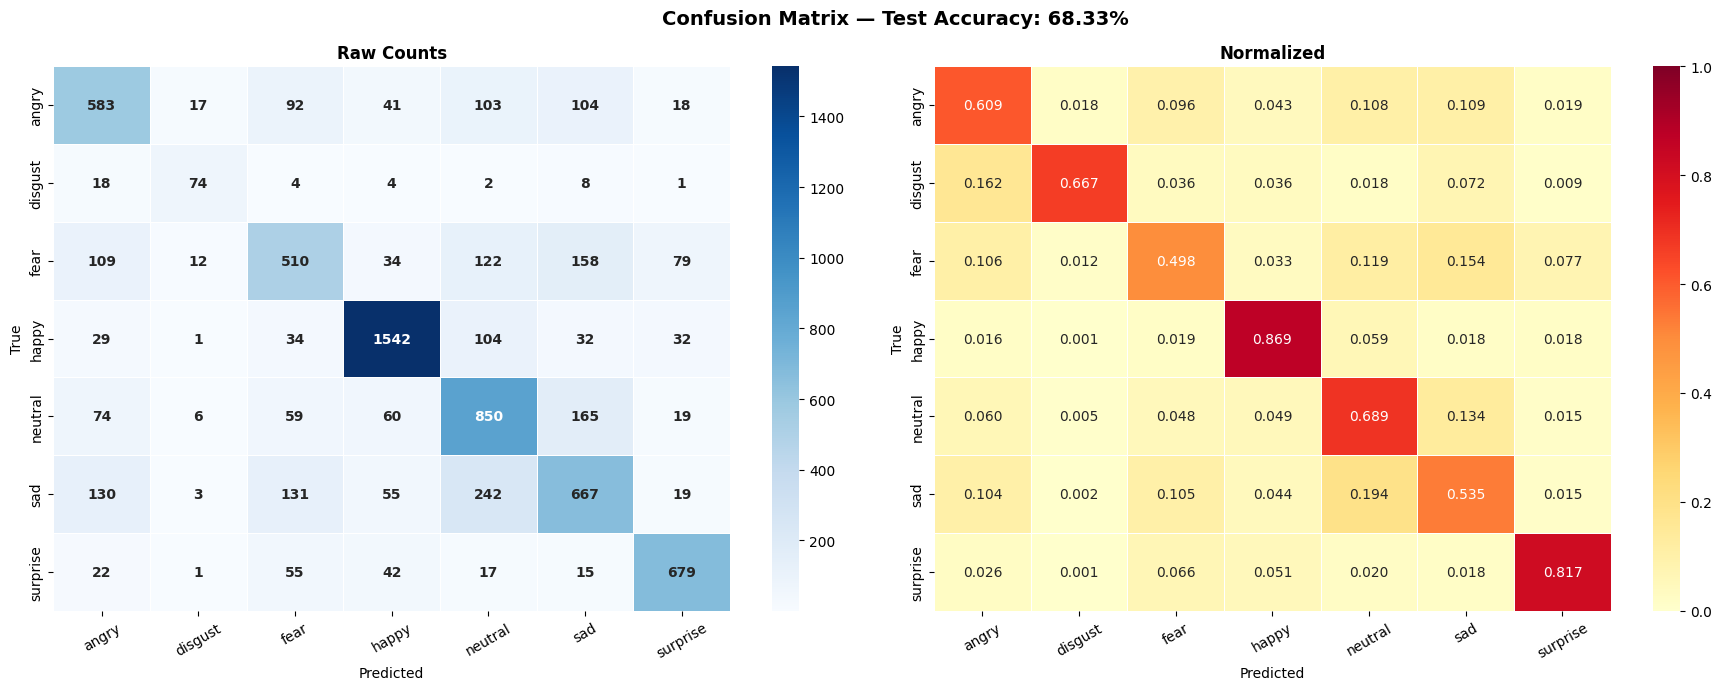

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/plots/13_confusion_matrix.png


In [46]:
# Confusion matrix — raw dan normalized
cm      = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle(f'Confusion Matrix — Test Accuracy: {test_acc*100:.2f}%',
             fontsize=14, fontweight='bold')

sns.heatmap(cm, annot=True, fmt='d', xticklabels=EMOTIONS, yticklabels=EMOTIONS,
            cmap='Blues', ax=axes[0], linewidths=0.5, annot_kws={'size': 10, 'weight': 'bold'})
axes[0].set_title('Raw Counts', fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')
axes[0].tick_params(axis='x', rotation=30)

sns.heatmap(cm_norm, annot=True, fmt='.3f', xticklabels=EMOTIONS, yticklabels=EMOTIONS,
            cmap='YlOrRd', ax=axes[1], linewidths=0.5, vmin=0, vmax=1,
            annot_kws={'size': 10})
axes[1].set_title('Normalized', fontweight='bold')
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('True')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/13_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {PLOT_DIR}/13_confusion_matrix.png')

          Accuracy  Precision  Recall  F1-Score  N_test
Emotion                                                
angry       0.6086     0.6041  0.6086    0.6063     958
disgust     0.6667     0.6491  0.6667    0.6578     111
fear        0.4980     0.5763  0.4980    0.5343    1024
happy       0.8692     0.8673  0.8692    0.8682    1774
neutral     0.6894     0.5903  0.6894    0.6360    1233
sad         0.5349     0.5805  0.5349    0.5568    1247
surprise    0.8171     0.8017  0.8171    0.8093     831


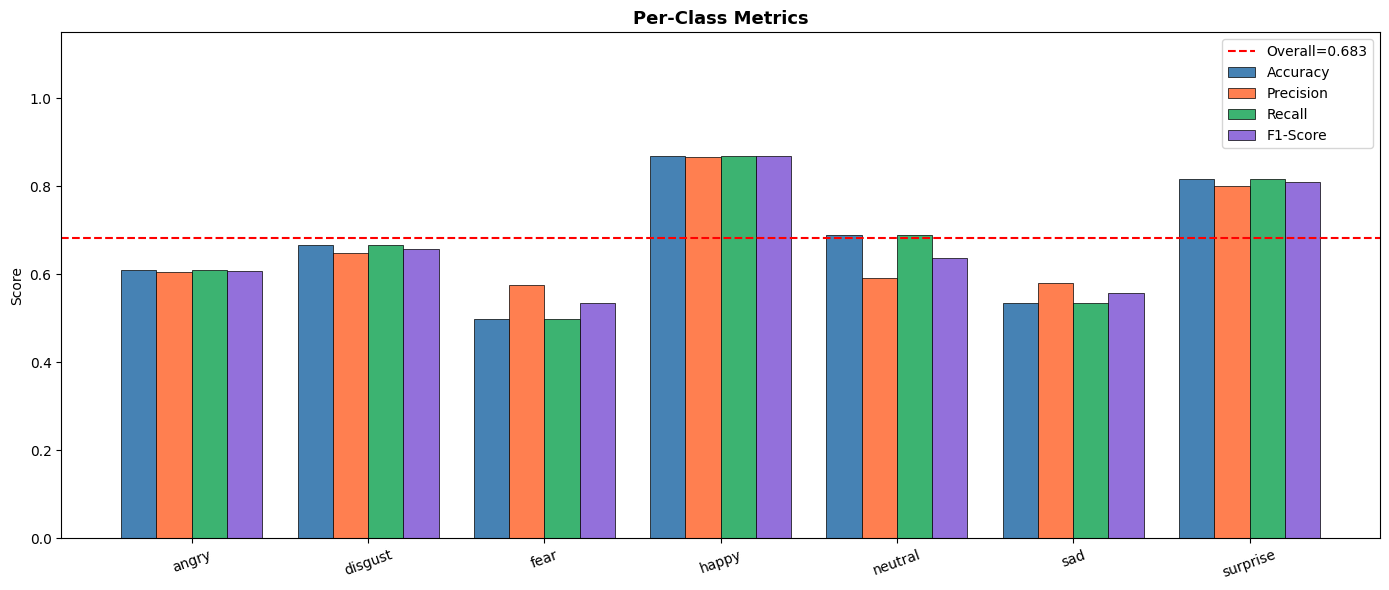

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/plots/14_per_class_metrics.png


In [47]:
# Per-class metrics — F1, precision, recall, accuracy
per_class_acc  = cm_norm.diagonal()
per_class_f1   = f1_score(y_true, y_pred, average=None, zero_division=0)
per_class_prec = precision_score(y_true, y_pred, average=None, zero_division=0)
per_class_rec  = recall_score(y_true, y_pred, average=None, zero_division=0)

per_class_df = pd.DataFrame({
    'Emotion':   EMOTIONS,
    'Accuracy':  per_class_acc,
    'Precision': per_class_prec,
    'Recall':    per_class_rec,
    'F1-Score':  per_class_f1,
    'N_test':    [int(np.sum(y_true==i)) for i in range(NUM_CLASSES)]
}).set_index('Emotion').round(4)

print(per_class_df.to_string())
per_class_df.to_csv(f'{OUTPUT_DIR}/per_class_metrics.csv')

fig, ax = plt.subplots(figsize=(14, 6))
x, w = np.arange(NUM_CLASSES), 0.2
ax.bar(x-1.5*w, per_class_acc,  w, label='Accuracy',  color='steelblue',       edgecolor='black', lw=0.5)
ax.bar(x-0.5*w, per_class_prec, w, label='Precision', color='coral',            edgecolor='black', lw=0.5)
ax.bar(x+0.5*w, per_class_rec,  w, label='Recall',    color='mediumseagreen',   edgecolor='black', lw=0.5)
ax.bar(x+1.5*w, per_class_f1,   w, label='F1-Score',  color='mediumpurple',     edgecolor='black', lw=0.5)
ax.set_xticks(x); ax.set_xticklabels(EMOTIONS, rotation=20)
ax.set_ylim(0, 1.15); ax.set_ylabel('Score')
ax.set_title('Per-Class Metrics', fontsize=13, fontweight='bold')
ax.axhline(test_acc, color='red', linestyle='--', lw=1.5, label=f'Overall={test_acc:.3f}')
ax.legend()
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/14_per_class_metrics.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {PLOT_DIR}/14_per_class_metrics.png')

## 8. Test-Time Augmentation (TTA)

Saya jalankan model 10 kali dengan augmentasi berbeda pada test set, lalu rata-ratakan probabilitas prediksi. TTA biasanya meningkatkan akurasi 0.5–2% tanpa retraining.

In [48]:
# TTA: buat 10 versi test_ds yang diaugmentasi, rata-ratakan output
tta_preds = np.zeros((len(test_paths), NUM_CLASSES))

# Tambahkan prediksi original (tanpa aug)
tta_preds += y_pred_prob

n_steps_test = len(test_paths) // BATCH_SIZE + 1

for t in range(TTA_STEPS):
    # Dataset test dengan augmentasi ringan
    tta_ds = (tf.data.Dataset.from_tensor_slices((test_paths,
               to_categorical(test_labels, NUM_CLASSES).astype(np.float32)))
              .map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
              .map(lambda img, lbl: (
                    tf.image.random_flip_left_right(
                    tf.image.random_brightness(img, 0.1)), lbl),
                   num_parallel_calls=tf.data.AUTOTUNE)
              .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

    preds_t = model.predict(tta_ds, steps=n_steps_test, verbose=0)
    tta_preds += preds_t[:len(test_paths)]

tta_preds  /= (TTA_STEPS + 1)
y_tta_pred  = np.argmax(tta_preds, axis=1)
tta_acc     = np.mean(y_tta_pred == y_true)

print(f'Accuracy standard : {test_acc:.4f}  ({test_acc*100:.2f}%)')
print(f'Accuracy TTA-{TTA_STEPS:2d}   : {tta_acc:.4f}  ({tta_acc*100:.2f}%)')
print(f'Improvement       : +{(tta_acc-test_acc)*100:.3f}%')

Accuracy standard : 0.6833  (68.33%)
Accuracy TTA-10   : 0.6925  (69.25%)
Improvement       : +0.919%


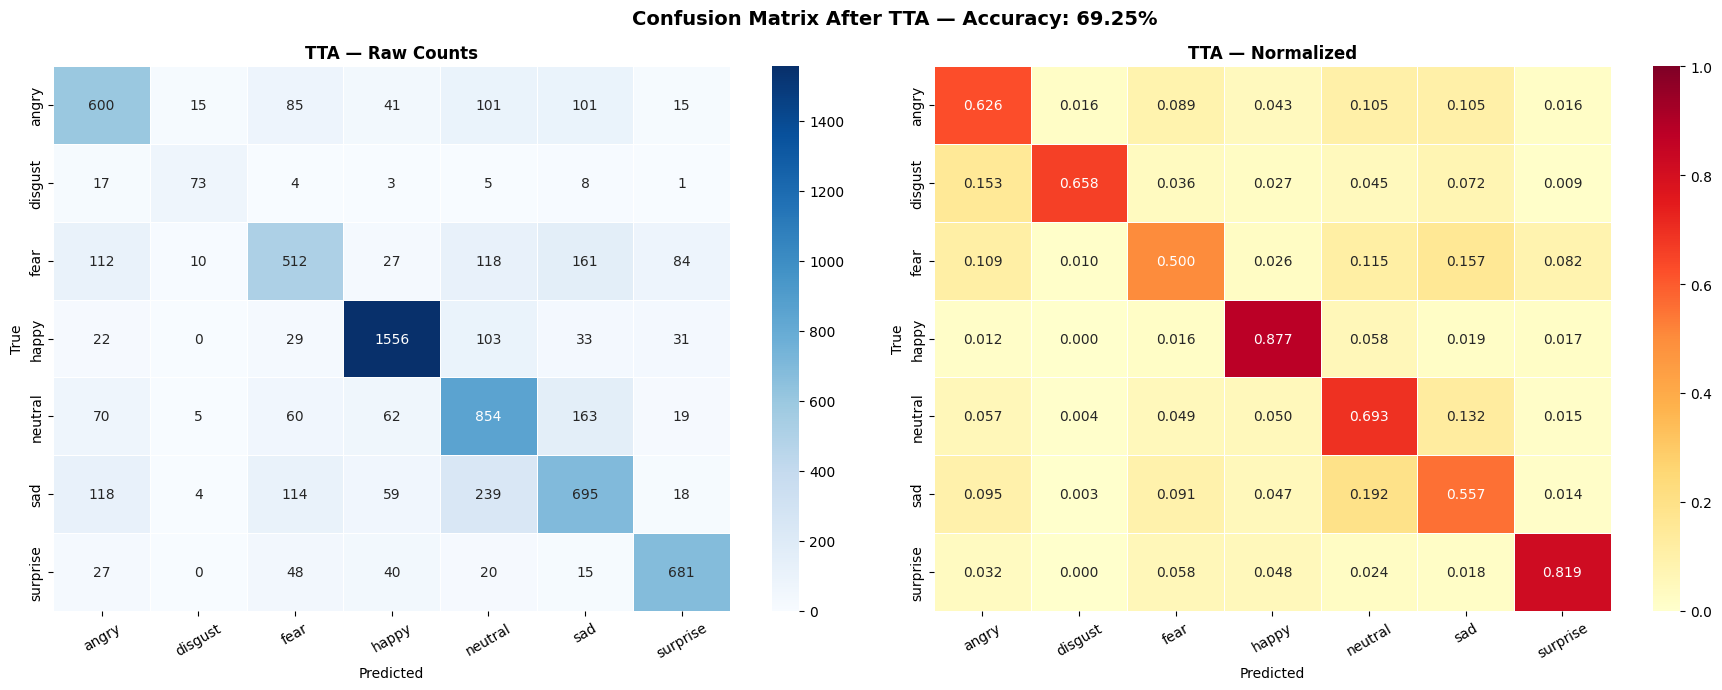

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/plots/15_confusion_matrix_tta.png


In [49]:
# Confusion matrix setelah TTA
cm_tta      = confusion_matrix(y_true, y_tta_pred)
cm_tta_norm = cm_tta.astype(float) / cm_tta.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle(f'Confusion Matrix After TTA — Accuracy: {tta_acc*100:.2f}%',
             fontsize=14, fontweight='bold')

sns.heatmap(cm_tta, annot=True, fmt='d', xticklabels=EMOTIONS, yticklabels=EMOTIONS,
            cmap='Blues', ax=axes[0], linewidths=0.5, annot_kws={'size': 10})
axes[0].set_title('TTA — Raw Counts', fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')
axes[0].tick_params(axis='x', rotation=30)

sns.heatmap(cm_tta_norm, annot=True, fmt='.3f', xticklabels=EMOTIONS, yticklabels=EMOTIONS,
            cmap='YlOrRd', ax=axes[1], linewidths=0.5, vmin=0, vmax=1,
            annot_kws={'size': 10})
axes[1].set_title('TTA — Normalized', fontweight='bold')
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('True')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/15_confusion_matrix_tta.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {PLOT_DIR}/15_confusion_matrix_tta.png')

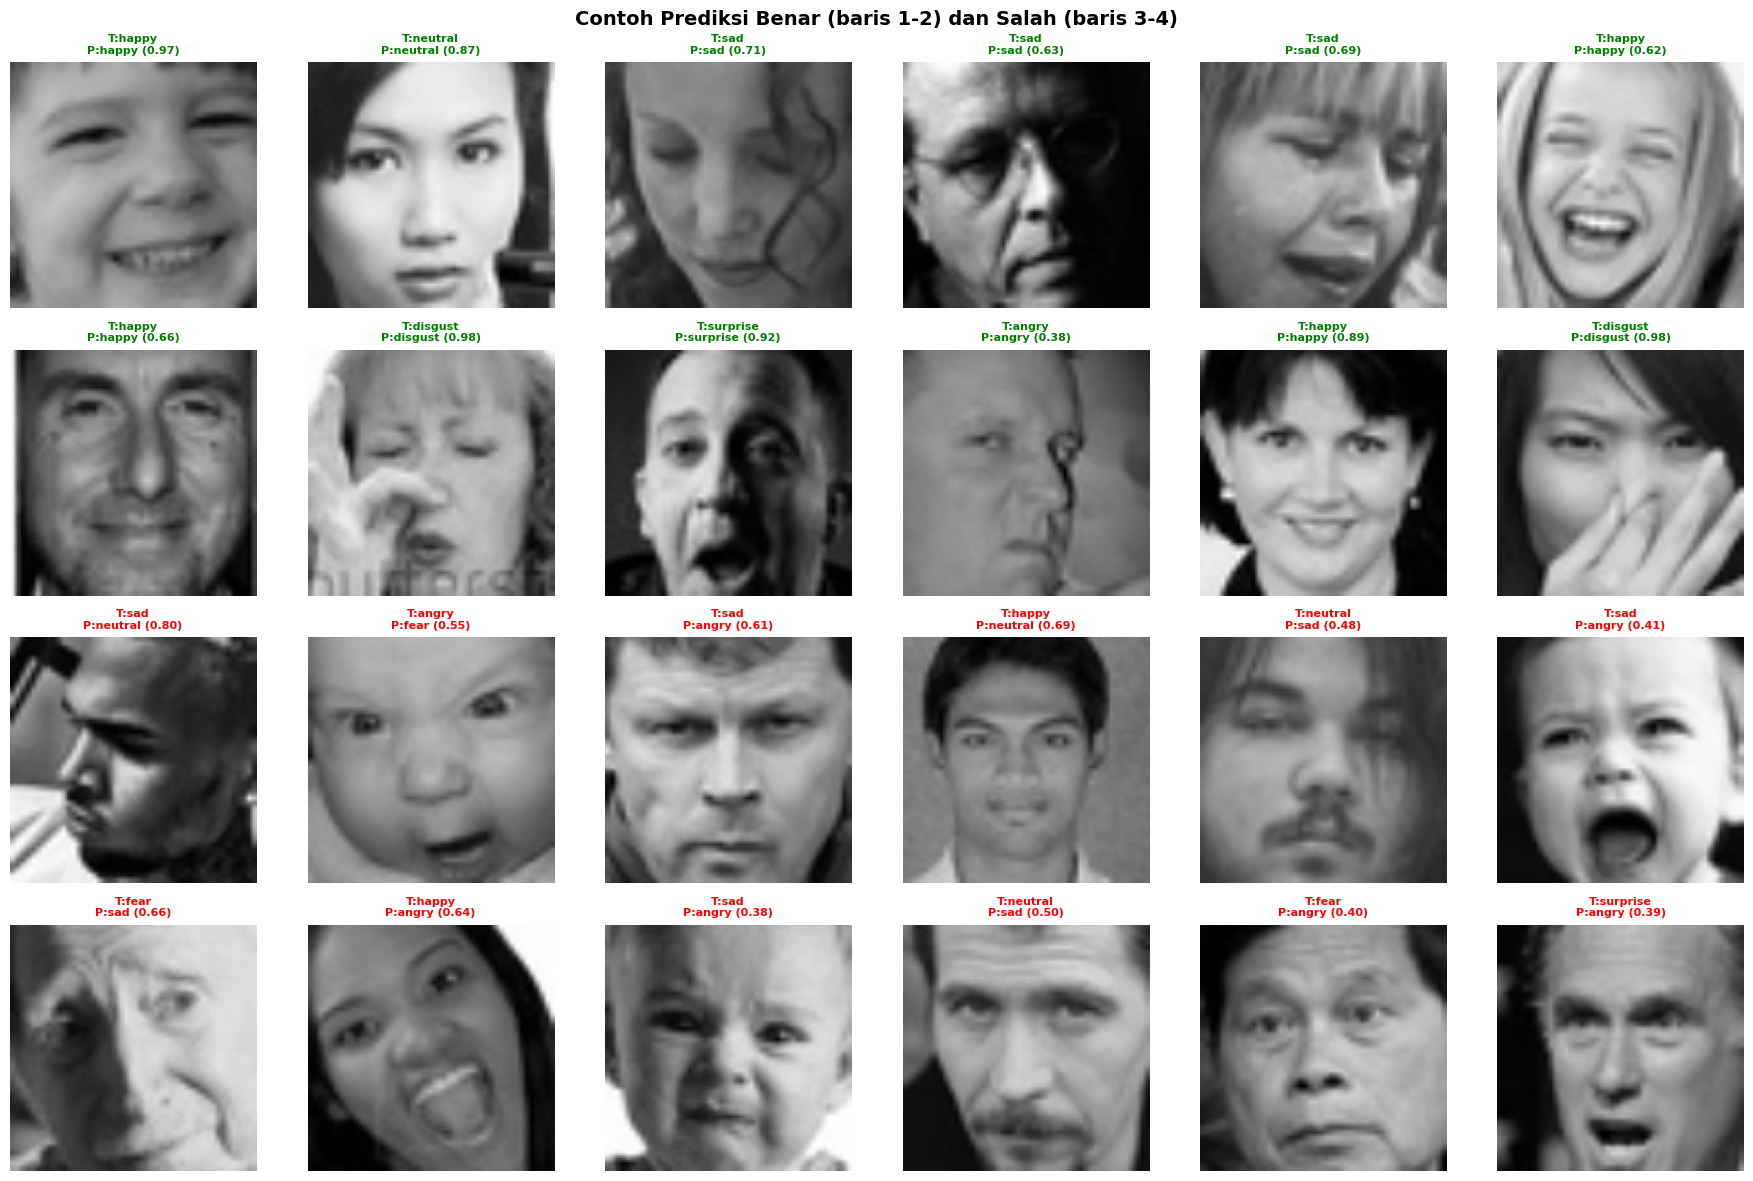

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/plots/16_prediction_samples.png


In [50]:
# Visualisasi prediksi benar dan salah — muat gambar langsung dari path
correct_idx = np.where(y_tta_pred == y_true)[0]
wrong_idx   = np.where(y_tta_pred != y_true)[0]

fig, axes = plt.subplots(4, 6, figsize=(18, 12))
fig.suptitle('Contoh Prediksi Benar (baris 1-2) dan Salah (baris 3-4)',
             fontsize=14, fontweight='bold')

for row_start, idx_pool, color in [(0, correct_idx, 'green'), (2, wrong_idx, 'red')]:
    sample = np.random.choice(idx_pool, size=12, replace=False)
    for j, sidx in enumerate(sample):
        r, c = row_start + j // 6, j % 6
        img = cv2.imread(test_paths[sidx])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (112, 112))
        axes[r, c].imshow(img)
        axes[r, c].set_title(
            f'T:{EMOTIONS[y_true[sidx]]}\nP:{EMOTIONS[y_tta_pred[sidx]]} ({tta_preds[sidx,y_tta_pred[sidx]]:.2f})',
            fontsize=8, color=color, fontweight='bold')
        axes[r, c].axis('off')

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/16_prediction_samples.png', dpi=120, bbox_inches='tight')
plt.show()
print(f'Saved -> {PLOT_DIR}/16_prediction_samples.png')

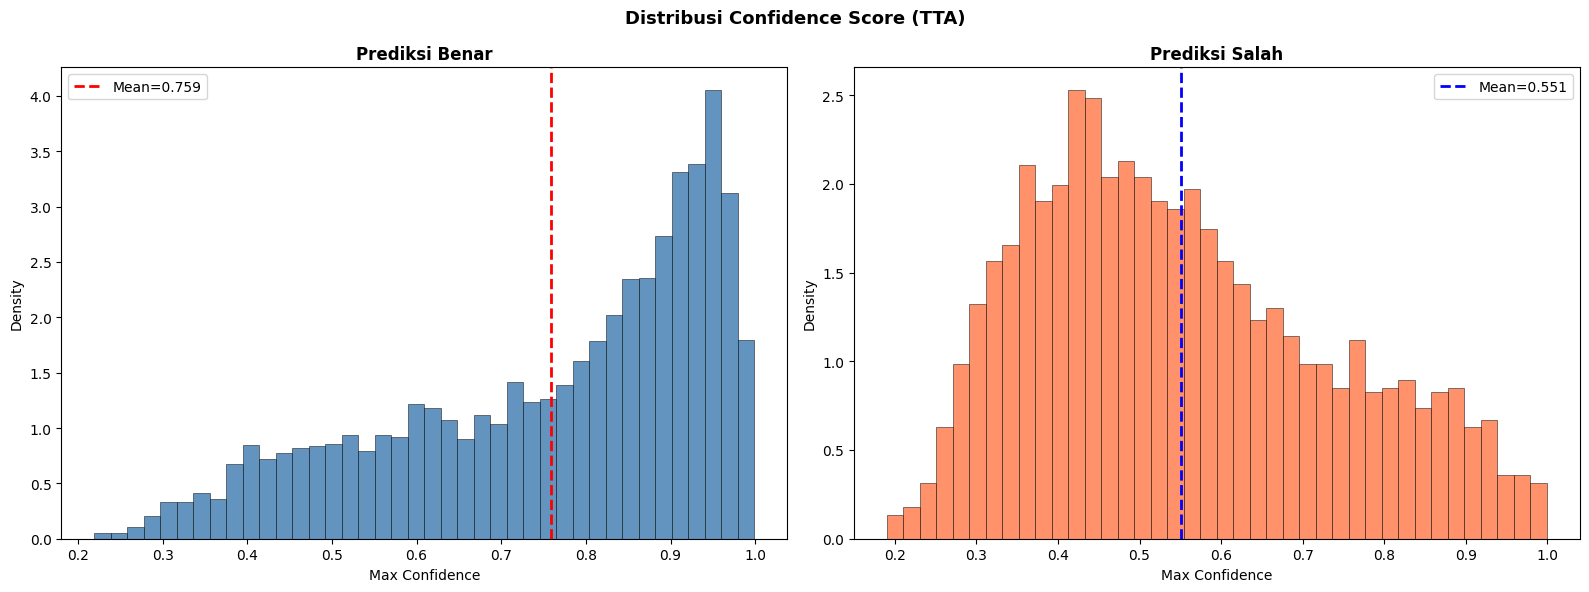

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/plots/17_confidence_distribution.png


In [51]:
# Distribusi confidence score prediksi benar vs salah
correct_conf = tta_preds[correct_idx].max(axis=1)
wrong_conf   = tta_preds[wrong_idx].max(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Distribusi Confidence Score (TTA)', fontsize=13, fontweight='bold')

axes[0].hist(correct_conf, bins=40, color='steelblue', alpha=0.85, edgecolor='black', lw=0.4, density=True)
axes[0].axvline(correct_conf.mean(), color='red', linestyle='--', lw=2,
                label=f'Mean={correct_conf.mean():.3f}')
axes[0].set_title('Prediksi Benar', fontweight='bold')
axes[0].set_xlabel('Max Confidence'); axes[0].set_ylabel('Density'); axes[0].legend()

axes[1].hist(wrong_conf, bins=40, color='coral', alpha=0.85, edgecolor='black', lw=0.4, density=True)
axes[1].axvline(wrong_conf.mean(), color='blue', linestyle='--', lw=2,
                label=f'Mean={wrong_conf.mean():.3f}')
axes[1].set_title('Prediksi Salah', fontweight='bold')
axes[1].set_xlabel('Max Confidence'); axes[1].set_ylabel('Density'); axes[1].legend()

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/17_confidence_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {PLOT_DIR}/17_confidence_distribution.png')

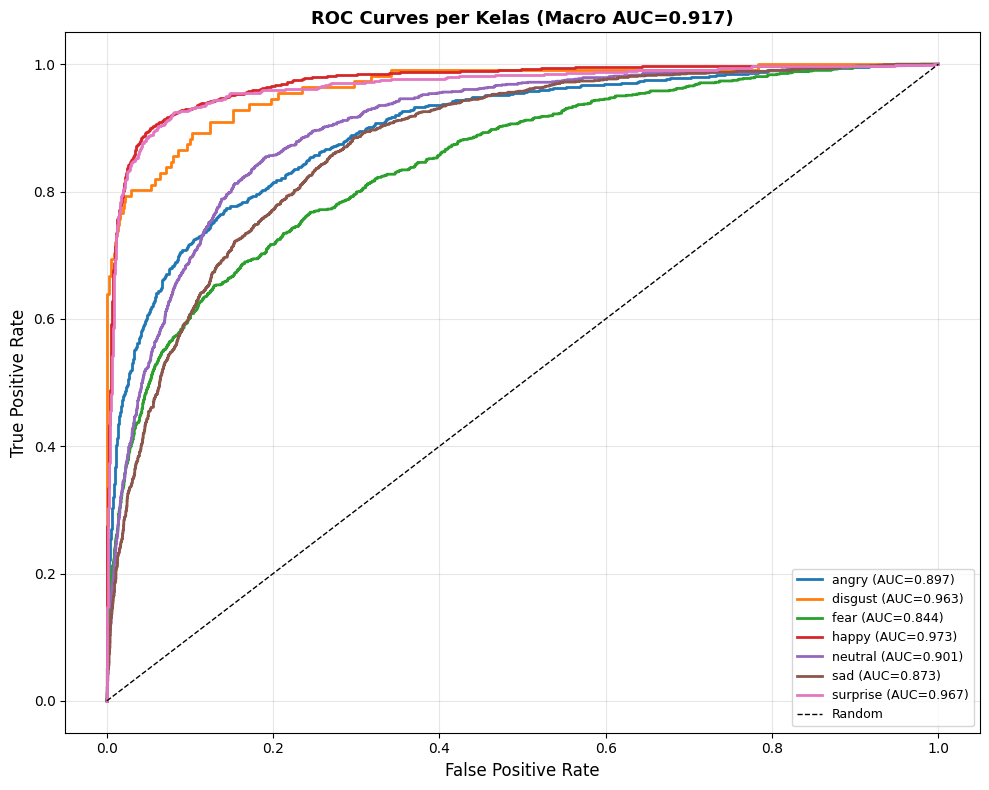

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/plots/18_roc_curves.png
Macro AUC: 0.9168


In [52]:
# ROC Curve per kelas
y_true_bin = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
palette    = sns.color_palette('tab10', NUM_CLASSES)

fig, ax = plt.subplots(figsize=(10, 8))
macro_auc = 0
for i, (emotion, color) in enumerate(zip(EMOTIONS, palette)):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], tta_preds[:, i])
    roc_auc = auc(fpr, tpr)
    macro_auc += roc_auc
    ax.plot(fpr, tpr, color=color, lw=2, label=f'{emotion} (AUC={roc_auc:.3f})')

macro_auc /= NUM_CLASSES
ax.plot([0,1],[0,1],'k--', lw=1, label='Random')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title(f'ROC Curves per Kelas (Macro AUC={macro_auc:.3f})', fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/18_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {PLOT_DIR}/18_roc_curves.png')
print(f'Macro AUC: {macro_auc:.4f}')

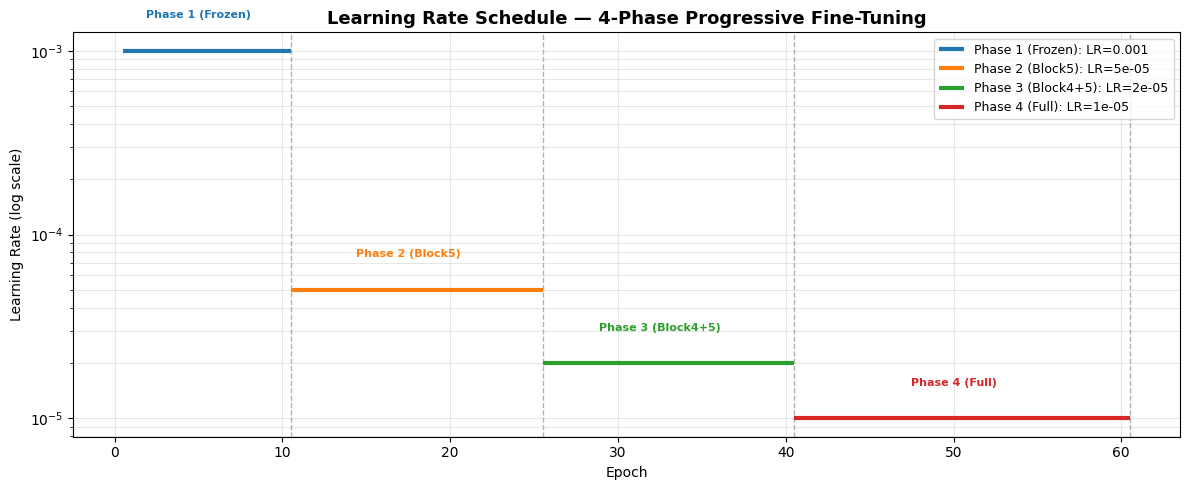

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/plots/19_lr_schedule.png


In [53]:
# Visualisasi learning rate schedule — untuk dokumentasi laporan
phase_data = [
    ('Phase 1 (Frozen)',   EPOCHS_FROZEN, LR_FROZEN),
    ('Phase 2 (Block5)',   EPOCHS_FT1,    LR_FT1),
    ('Phase 3 (Block4+5)', EPOCHS_FT2,    LR_FT2),
    ('Phase 4 (Full)',     EPOCHS_FT3,    LR_FT3),
]

fig, ax = plt.subplots(figsize=(12, 5))
current = 0
palette = sns.color_palette('tab10', 4)
for i, (name, n_ep, lr) in enumerate(phase_data):
    ax.hlines(lr, current+0.5, current+n_ep+0.5, colors=palette[i], lw=3, label=f'{name}: LR={lr}')
    ax.axvline(current+n_ep+0.5, color='gray', linestyle='--', lw=1, alpha=0.6)
    ax.text(current+n_ep/2, lr*1.5, name, ha='center', fontsize=8,
            color=palette[i], fontweight='bold')
    current += n_ep

ax.set_yscale('log')
ax.set_xlabel('Epoch'); ax.set_ylabel('Learning Rate (log scale)')
ax.set_title('Learning Rate Schedule — 4-Phase Progressive Fine-Tuning',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=0.3, which='both')

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/19_lr_schedule.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {PLOT_DIR}/19_lr_schedule.png')

## 9. Simpan Model

Tiga format export:
- **`.keras`** — native Keras (untuk fine-tuning lanjut)
- **`.h5`** — HDF5 legacy (kompatibilitas luas)
- **`.tflite`** — INT8 quantized untuk Android deployment

In [54]:
keras_path = f'{MODEL_DIR}/fer_vgg16_attention_best.keras'
model.save(keras_path)
print(f'Saved .keras -> {keras_path}')
print(f'Size         : {os.path.getsize(keras_path)/1e6:.1f} MB')

Saved .keras -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/fer_vgg16_attention_best.keras
Size         : 60.2 MB


In [55]:
h5_path = f'{MODEL_DIR}/fer_vgg16_attention_best.h5'
model.save(h5_path)
print(f'Saved .h5    -> {h5_path}')
print(f'Size         : {os.path.getsize(h5_path)/1e6:.1f} MB')

Saved .h5    -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/fer_vgg16_attention_best.h5
Size         : 60.2 MB


In [56]:
# Konversi ke TFLite INT8 post-training quantization untuk Android
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# Representative dataset dari test paths (tidak butuh load semua ke RAM)
def representative_dataset():
    count = 0
    for path in test_paths:
        if count >= 200:
            break
        raw = tf.io.read_file(path)
        img = tf.image.decode_image(raw, channels=3, expand_animations=False)
        img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
        img = tf.cast(img, tf.float32)
        img = vgg_preprocess(img)
        yield [tf.expand_dims(img, 0)]
        count += 1

converter.representative_dataset   = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type      = tf.float32
converter.inference_output_type     = tf.float32

tflite_model = converter.convert()

tflite_path = f'{MODEL_DIR}/fer_vgg16_attention_best.tflite'
with open(tflite_path, 'wb') as f:
    f.write(tflite_model)

h5_size     = os.path.getsize(h5_path)
tflite_size = os.path.getsize(tflite_path)
print(f'Saved .tflite -> {tflite_path}')
print(f'Size          : {tflite_size/1e6:.1f} MB')
print(f'Compression   : {h5_size/tflite_size:.1f}x lebih kecil dari .h5')

INFO:tensorflow:Assets written to: /tmp/tmp99u7eg8j/assets


INFO:tensorflow:Assets written to: /tmp/tmp99u7eg8j/assets


Saved artifact at '/tmp/tmp99u7eg8j'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_44')
Output Type:
  TensorSpec(shape=(None, 7), dtype=tf.float32, name=None)
Captures:
  131600177861776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131600177860624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131600177858896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131600177856592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131600177861392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131600177861968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131600177862544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131600177862352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131600177863120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131600177862928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13160383752

W0000 00:00:1776528634.036724   27879 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1776528634.036736   27879 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1776528634.036938   27879 reader.cc:83] Reading SavedModel from: /tmp/tmp99u7eg8j
I0000 00:00:1776528634.038196   27879 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1776528634.038203   27879 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp99u7eg8j
I0000 00:00:1776528634.048620   27879 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1776528634.050816   27879 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1776528634.162300   27879 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp99u7eg8j
I0000 00:00:1776528634.181698   27879 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 144767 microseconds.


Saved .tflite -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/fer_vgg16_attention_best.tflite
Size          : 15.2 MB
Compression   : 4.0x lebih kecil dari .h5


fully_quantize: 0, inference_type: 6, input_inference_type: FLOAT32, output_inference_type: FLOAT32
W0000 00:00:1776528679.793202   27879 flatbuffer_export.cc:3851] Skipping runtime version metadata in the model. This will be generated by the exporter.


In [57]:
# Validasi TFLite — bandingkan output dengan Keras model
interpreter = tf.lite.Interpreter(model_path=tflite_path)
interpreter.allocate_tensors()
inp_det = interpreter.get_input_details()
out_det = interpreter.get_output_details()

n_valid, correct = 100, 0
for i in range(n_valid):
    raw = tf.io.read_file(test_paths[i])
    img = tf.image.decode_image(raw, channels=3, expand_animations=False)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32)
    inp = tf.expand_dims(vgg_preprocess(img), 0).numpy()
    interpreter.set_tensor(inp_det[0]['index'], inp)
    interpreter.invoke()
    pred = interpreter.get_tensor(out_det[0]['index'])
    if np.argmax(pred) == y_true[i]:
        correct += 1

tflite_acc = correct / n_valid
print(f'TFLite accuracy ({n_valid} samples) : {tflite_acc:.4f} ({tflite_acc*100:.2f}%)')
print(f'Keras  accuracy (full test TTA)    : {tta_acc:.4f} ({tta_acc*100:.2f}%)')
print('Model TFLite siap untuk deployment Android.')

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


TFLite accuracy (100 samples) : 0.6100 (61.00%)
Keras  accuracy (full test TTA)    : 0.6925 (69.25%)
Model TFLite siap untuk deployment Android.


In [58]:
# Metadata model untuk Android — label mapping, input spec, accuracy
metadata = {
    'model_name':        'fer_vgg16_attention',
    'version':           'v2',
    'framework':         f'TensorFlow {tf.__version__}',
    'dataset':           'FER2013 + CK+ Extended',
    'num_classes':       NUM_CLASSES,
    'labels':            EMOTIONS,
    'input_shape':       [1, IMG_SIZE, IMG_SIZE, 3],
    'input_dtype':       'float32',
    'preprocessing':     'VGG16: RGB->BGR, subtract [103.939, 116.779, 123.68]',
    'test_accuracy':     round(float(test_acc), 4),
    'tta_accuracy':      round(float(tta_acc), 4),
    'macro_auc':         round(float(macro_auc), 4),
    'tta_steps':         TTA_STEPS,
    'architecture':      'VGG-16 + SE Block (Hu 2018) + Spatial Attention (CBAM Woo 2018)',
    'training_strategy': 'Progressive fine-tuning 4 phases',
    'hyperparameters':   best_hp_dict,
    'class_weights':     class_weight_dict,
}

with open(f'{OUTPUT_DIR}/model_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)
print(f'Saved -> {OUTPUT_DIR}/model_metadata.json')
print(json.dumps({k:v for k,v in metadata.items() if k != 'class_weights'}, indent=2))

Saved -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/model_metadata.json
{
  "model_name": "fer_vgg16_attention",
  "version": "v2",
  "framework": "TensorFlow 2.21.0",
  "dataset": "FER2013 + CK+ Extended",
  "num_classes": 7,
  "labels": [
    "angry",
    "disgust",
    "fear",
    "happy",
    "neutral",
    "sad",
    "surprise"
  ],
  "input_shape": [
    1,
    224,
    224,
    3
  ],
  "input_dtype": "float32",
  "preprocessing": "VGG16: RGB->BGR, subtract [103.939, 116.779, 123.68]",
  "test_accuracy": 0.6833,
  "tta_accuracy": 0.6925,
  "macro_auc": 0.9168,
  "tta_steps": 10,
  "architecture": "VGG-16 + SE Block (Hu 2018) + Spatial Attention (CBAM Woo 2018)",
  "training_strategy": "Progressive fine-tuning 4 phases",
  "hyperparameters": {
    "dense_units": 512,
    "dropout_rate": 0.6000000000000001,
    "l2_reg": 0.0005,
    "se_ratio": 16,
    "num_dense_layers": 1,
    "learning_rate": 0.002
  }
}


## 10. Ringkasan Eksperimen

In [59]:
print('=' * 68)
print('   RINGKASAN — FER VGG-16 + Attention (FER2013 + CK+) v2')
print('=' * 68)
print(f'  Dataset        : FER2013 + CK+ Extended')
print(f'  Train paths    : {len(train_paths)}  |  Val: {len(val_paths)}  |  Test: {len(test_paths)}')
print(f'  Pipeline       : tf.data on-the-fly (RAM peak: ~{ram_gb():.1f} GB)')
print(f'  Architecture   : VGG-16 + SE Block + Spatial Attention')
print(f'  HP Tuning      : Bayesian Optimization (20 trials x 8 epochs)')
print(f'  Best HP        : {best_hp_dict}')
print()
print(f'  Test Accuracy (standard) : {test_acc*100:.2f}%')
print(f'  Test Accuracy (TTA-{TTA_STEPS})   : {tta_acc*100:.2f}%')
print(f'  Macro AUC                : {macro_auc:.4f}')
print()
print('  Models saved:')
print(f'    .keras  -> {MODEL_DIR}/fer_vgg16_attention_best.keras')
print(f'    .h5     -> {MODEL_DIR}/fer_vgg16_attention_best.h5')
print(f'    .tflite -> {MODEL_DIR}/fer_vgg16_attention_best.tflite')
print('=' * 68)

print('\nSemua file output:')
for root, dirs, files in os.walk(OUTPUT_DIR):
    if 'ck_temp' in root:
        continue  # skip folder temp
    level  = root.replace(OUTPUT_DIR, '').count(os.sep)
    indent = '  ' * level
    print(f'{indent}{os.path.basename(root)}/')
    for fname in sorted(files):
        fpath    = os.path.join(root, fname)
        fsize    = os.path.getsize(fpath)
        size_str = f'{fsize/1e6:.1f}MB' if fsize > 1e6 else f'{fsize/1e3:.0f}KB'
        print(f'{indent}  {fname}  ({size_str})')

   RINGKASAN — FER VGG-16 + Attention (FER2013 + CK+) v2
  Dataset        : FER2013 + CK+ Extended
  Train paths    : 26649  |  Val: 2962  |  Test: 7178
  Pipeline       : tf.data on-the-fly (RAM peak: ~12.0 GB)
  Architecture   : VGG-16 + SE Block + Spatial Attention
  HP Tuning      : Bayesian Optimization (20 trials x 8 epochs)
  Best HP        : {'dense_units': 512, 'dropout_rate': 0.6000000000000001, 'l2_reg': 0.0005, 'se_ratio': 16, 'num_dense_layers': 1, 'learning_rate': 0.002}

  Test Accuracy (standard) : 68.33%
  Test Accuracy (TTA-10)   : 69.25%
  Macro AUC                : 0.9168

  Models saved:
    .keras  -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/fer_vgg16_attention_best.keras
    .h5     -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/fer_vgg16_attention_best.h5
    .tflite -> /media/mdprana/A02A34FD2A34D1D0/1. Skripsi/model/wajah/versi 5/output/models/fer_vgg16_attention_best.tflite

Semua file outpu